[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_AnomalyDetection5G_Alalyan2026.ipynb)

# QSVM and VQC for anomaly detection in 5G and beyond networks: Alalyan et al. (2026) step by step

**Paper.** F. Alalyan, J. Saidi, W. Jaafar and R. Langar, *Quantum Machine Learning for Anomaly Detection in 5G and Beyond Mobile Networks*, 2026 Global Information Infrastructure and Networking Symposium (GIIS), IEEE, 2026. DOI: [10.1109/GIIS69881.2026.11585757](https://doi.org/10.1109/GIIS69881.2026.11585757).

**What this notebook does.** It rebuilds the paper's quantum network intrusion detection pipeline end to end:
frequency-encode the categorical flow features, scale to [0, 1], compress to **4 features** (= 4 qubits) with **PCA, a basic autoencoder (BE) or a variational autoencoder (VAE)**, scale again for the quantum circuit, and classify with a **QSVM** (ZZ feature map, quantum kernel, classical SVM solver) or a **VQC** (amplitude encoding, trained variational circuit). It then re-runs the paper's experiments on **NSL-KDD** and **UNSW-NB15 (NB15)**: Tables I, II, III, IV, V, VI, the overlap experiment, and the timing claims. Everything is compared with a classical SVM (polynomial kernel, as in the paper) and a random forest on the *same* 4 inputs.

**How to run.** Open in Google Colab, choose a **CPU runtime** (no GPU needed), then *Runtime -> Run all*. The first cell installs pinned versions; if Colab asks for a session restart, restart and run all again. `FAST_MODE = True` (default) finishes in a few minutes; `FAST_MODE = False` uses the paper's 20 random extractions per setting and larger training pools for the autoencoders (see the configuration cell for the exact budgets).

**What you get at the end.** Re-drawn versions of the paper's tables and figures (accuracy tables, accuracy box plots, the data-point distributions of the outlier case), the circuits that are actually executed, and a final claim-by-claim table that states for every number in the paper whether this notebook *reproduced* it, *did not reach* it, *exceeded* it, or *cannot check* it.

**A note on the word "5G".** As the paper itself says in a footnote, the datasets (NSL-KDD, NB15) are **not 5G-specific**: the pipeline only needs flow-level features. The 5G O-RAN testbed the authors mention is future work and is not part of this notebook.

## The paper in one page

**Problem.** Detect cyberattacks in 5G/B5G networks (binary: *attack* vs *legitimate*) with a quantum model that is small enough for today's noisy devices: few qubits, shallow circuits.

**Decision.** Per network flow: attack (1) or normal (0).

**Method.**
1. *Preprocessing:* categorical features -> frequency encoding; all features -> [0, 1].
2. *Feature fusion* to 4 features: PCA (4 components), basic autoencoder (BE) or VAE with a 16-neuron intermediate layer and a **4-neuron bottleneck**, 72 epochs, batch size 200.
3. *Normalisation* of the 4 features for the quantum circuit.
4. *QSVM:* `ZZFeatureMap` (Hadamards + `U(x)` twice, Eq. 1), quantum kernel from a Qiskit `AerSimulator`, classical SVM solver on the kernel matrix. Baseline: classical SVM with a **polynomial** kernel.
5. *VQC:* implemented in PennyLane with **amplitude encoding** (4 features on 2 qubits).

**Data.** NSL-KDD (125,973 flows: 67,343 normal, 58,630 attack, 42 features) and NB15 (1,140,043 flows: 893,724 normal, 246,319 attack, 49 features of which 6 are dropped). All attack types are merged into one class.

**Protocol.** Draw `Z = X + Y` random points (X for training, Y for testing, split `(alpha, beta)`), repeat **20 times**, report the **mean accuracy**. Vary `Z` (150/250 for NSL-KDD, 200/300 for NB15), the split, the fusion method and the attack/normal mix `(gamma1, gamma2)`.

**Claims to check.**
- Table I (NSL-KDD, PCA): QSVM beats SVM; accuracy grows with `Z` and with the training fraction: 0.85/0.88 (66.7/33.3), 0.87/0.90 (75/25), 0.90/0.92 (80/20) for `Z` = 150/250. SVM = 0.80 (quoted from Gouveia and Correia 2020).
- Table II (NB15, PCA): QSVM 0.68 / 0.70 (75/25) and 0.71 / 0.73 (80/20) for `Z` = 200/300; SVM = 0.60.
- Table III (NSL-KDD, QSVM, 80/20): the mix 55% attack / 45% normal is best for every fusion method; VAE (up to 0.96) > BE (0.95) > PCA (0.94).
- Fig. 2-3: VAE has the smallest spread over the 20 draws.
- Table IV: for an outlier draw (BE, 50/50, accuracy 0.70) adding 5% *intra-class* attack points gives 0.83, adding 10% *inter-class* points gives 0.50.
- Table V (NB15, QSVM + VAE): 0.84-0.89 depending on the mix, best at 55/45.
- Overlap experiment: on 100 training / 50 test points from strongly overlapping zones SVM reaches 0.32-0.59 in ~0.015 s, QSVM 0.50-0.68 in ~4.11 s.
- Table VI (VQC, amplitude encoding, `Z` = 250, NSL-KDD): 0.60 / 0.67 / 0.72 for the mixes 60/40, 50/50, 55/45, worse than SVM.
- Reconstruction errors on NSL-KDD: BE MSE 0.0059, VAE 0.0051, PCA 0.008. QSVM circuit with 4 qubits and depth 2.
- Inference time on NSL-KDD: SVM 460 s, QSVM 73 s (`Z` = 150) and 42 s (`Z` = 250).

### What follows the paper and what had to be chosen

The paper leaves many details open (it is a short symposium paper). Every row marked *CHOICE* is also marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| NSL-KDD data | 125,973 flows, 42 features | Official `KDDTrain+` (125,973 flows) from the public GitHub mirror `defcom17/NSL_KDD`; 41 features (the extra "difficulty level" column is dropped because it is derived from the label). |
| NB15 data | 1,140,043 flows (893,724 normal / 246,319 attack), 49 features | The **public official training + testing partition** (257,673 flows) from the Hugging Face mirror `research-simulation26/unsw-nb15-parquet` (fallback `Mireu-Lab/UNSW-NB15`). The paper's 1.14 M-flow subset is not available. CHOICE: attack flows are randomly sub-sampled so that the attack share equals the paper's 21.6%. The six features the paper drops are dropped (`srcip`, `dstip`, `attack_cat`, `ct_flw_http_mthd`, `is_ftp_login`, `ct_ftp_cmd`); the partition has no IP columns, leaving 39 features. |
| Binary label | all attacks merged | same (original attack families are kept for the plots) |
| Categorical encoding | frequency encoding | frequency encoding; frequencies are estimated on the *fit pool* only (CHOICE) |
| Where PCA / BE / VAE are fitted | not stated | **CHOICE:** once, on an unlabelled *fit pool* of flows that is disjoint from every flow ever used to train or test a classifier. No labels and no test flow are used for fitting any transform. |
| PCA / BE / VAE size | 4 components; 16-neuron layer + 4-neuron bottleneck; 72 epochs, batch 200 | same. CHOICE: ReLU activations, Adam, sigmoid output; VAE loss = reconstruction MSE + `BETA_KL` x KL (the paper does not give the loss weighting). |
| Normalisation for the circuit | "normalised" | **CHOICE:** per extraction, `MinMaxScaler` fitted on the training split, test values clipped to [0, 1], then multiplied by `ANGLE_SCALE = pi`. |
| QSVM circuit | `ZZFeatureMap`, 4 qubits, "depth 2" | `zz_feature_map(4, reps=2, entanglement="full")`. CHOICE: entanglement `full` (Qiskit's default; the paper does not say) and `reps = 2` (the "depth 2" of the paper and the `U(x) H U(x) H` structure of Eq. 1). |
| Kernel evaluation | Qiskit `AerSimulator` | Exact statevector kernel (a NumPy implementation of the same circuit, asserted equal to Qiskit's statevector and to a shot-based `AerSimulator` run; see the circuit section). The shots-based Aer kernel would add sampling noise but is far too slow for ~1,000 runs. |
| SVM solver for the QSVM | classical SVM on the kernel matrix | `sklearn.svm.SVC(kernel="precomputed", C=1)`. |
| Classical baseline | polynomial-kernel SVM with LiquidSVM on the whole dataset (numbers quoted from Gouveia and Correia) | `SVC(kernel="poly", degree=3)` on the same 4 inputs, (a) trained on a large sample of the dataset (the paper's setting), (b) on the identical `Z` points (the fair comparison the paper itself asks for at the end). A random forest and an RBF SVM are added on the same inputs. |
| Random extractions | 20 | 20 when `FAST_MODE = False`, 5 when `FAST_MODE = True` |
| Class mix `(gamma1, gamma2)` | share of attack / normal in the `Z` points | same; Tables I and II use the natural mix of the sampled pool |
| Table IV | outlier + 5% / 10% extra attack points, "intra-class" (near the attack points) and "inter-class" (near the normal points) | CHOICE: nearest candidates by mean distance to the 5 nearest training points of the respective class, candidates drawn from the extraction pool; averaged over the worst draws; a random-points control is added. |
| Overlap experiment | "highly overlapping zones", 100 train / 50 test, 20 repeats | CHOICE: zones = flows whose 15 nearest neighbours (in PCA space) are at least 40% of the opposite class. |
| VQC | PennyLane, amplitude encoding, ansatz / optimiser / epochs not given | CHOICE: 2 qubits, `AmplitudeEmbedding` (4 amplitudes), 3 `StronglyEntanglingLayers`, ``<Z_0>`` as output, mean-squared-error loss, Adam (lr 0.1), full batch. |

In [1]:
# Installs pinned to the versions this notebook was tested with. Skipped locally when they are already present.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules

def _needs_install():
    try:
        import qiskit, qiskit_aer, qiskit_machine_learning, pennylane
        return False
    except Exception:
        return True

if IN_COLAB or _needs_install():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "qiskit-aer==0.17.2",
                           "pennylane==0.45.1", "pylatexenc", "huggingface_hub", "pyarrow"])
    print("Installed. If Colab complains about binary incompatibility, restart the session and Run all again.")
else:
    print("Required packages already available; nothing to install.")

Required packages already available; nothing to install.


## 0. Configuration

One cell holds every tunable constant. `FAST_MODE = True` is the class-demo budget; the commented full-run values follow the paper (20 random extractions per setting).

In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: about 5-10 min. False: 20 random extractions per setting, larger fit pools (see below)
SEED      = 42              # one seed for numpy, torch, sklearn, Qiskit, PennyLane
N_QUBITS  = 4               # paper: 4 features = 4 qubits
FM_REPS   = 2               # paper: "depth 2" of the ZZ feature map (U(x) H U(x) H)
ENTANGLEMENT = "full"       # CHOICE: Qiskit's default for ZZFeatureMap; the paper does not say
ANGLE_SCALE  = 3.141592653589793   # CHOICE: features in [0, 1] are multiplied by pi before entering the circuit
QSVM_C    = 1.0             # CHOICE: sklearn default; the paper does not give C
SHOTS     = 4096            # shots for the AerSimulator cross-check of the kernel (the main runs use the exact statevector)
IBM_TOKEN = ""              # optional, unused here (no real-hardware cell; the paper ran simulators only)

if FAST_MODE:
    N_REPS      = 5         # paper: 20 random extractions
    POOL_FIT    = 4000      # unlabelled flows used to fit encoders / PCA / BE / VAE
    BIG_TRAIN   = 3000      # size of the "large training set" SVM baseline (paper: the whole dataset)
    BIG_TEST    = 3000
    OVERLAP_POOL = 6000     # flows scanned for strongly overlapping zones
    OVERLAP_REPS = 5
    N_OUTLIERS  = 3         # worst draws used for Table IV
    VQC_REPS    = 3
    VQC_STEPS   = 40
else:
    N_REPS      = 20
    POOL_FIT    = 20000
    BIG_TRAIN   = 20000
    BIG_TEST    = 10000
    OVERLAP_POOL = 20000
    OVERLAP_REPS = 20
    N_OUTLIERS  = 5
    VQC_REPS    = 10
    VQC_STEPS   = 80

AE_EPOCHS, AE_BATCH, AE_HIDDEN = 72, 200, 16       # paper: 72 epochs, batch 200, 16-neuron intermediate layer, 4-neuron bottleneck
AE_LR     = 3e-3            # CHOICE: Adam learning rate
BETA_KL   = 1e-3            # CHOICE: weight of the KL term in the VAE loss
NB15_ATTACK_FRACTION = 0.2161   # CHOICE: paper's NB15 prior (246,319 / 1,140,043); None keeps the partition's natural mix
TOL_ACC   = 0.02            # verdict tolerance on accuracies (project rule: within 2 accuracy points)

DATA_DIR  = "data"          # downloads are cached here (relative to the notebook / Colab working directory)
NSL_URLS  = ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
             "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"]
UNSW_REPO, UNSW_REPO_ALT = "research-simulation26/unsw-nb15-parquet", "Mireu-Lab/UNSW-NB15"
LOCAL_NSL = ""             # optional: path to your own copy of KDDTrain+.txt
print(f"FAST_MODE={FAST_MODE}  N_REPS={N_REPS}  POOL_FIT={POOL_FIT}")

FAST_MODE=False  N_REPS=20  POOL_FIT=20000


In [3]:
import os, time, itertools, warnings, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from sklearn.neighbors import NearestNeighbors
import torch, torch.nn as nn, torch.nn.functional as F_
import qiskit, qiskit_aer, qiskit_machine_learning, pennylane as qml
from qiskit import transpile
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC

warnings.filterwarnings("ignore")
torch.set_num_threads(2)
np.random.seed(SEED); torch.manual_seed(SEED); algorithm_globals.random_seed = SEED
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
print("qiskit", qiskit.__version__, "| aer", qiskit_aer.__version__, "| qiskit-ml", qiskit_machine_learning.__version__,
      "| pennylane", qml.__version__, "| torch", torch.__version__, "| numpy", np.__version__)

# Hugging Face token: only needed for gated datasets (the mirrors used here are public). In Colab add HF_TOKEN under Settings > Secrets.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("HF token available:", HF_TOKEN is not None)

qiskit 2.5.2 | aer 0.17.2 | qiskit-ml 0.9.1 | pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4
HF token available: True


## 1. Data: NSL-KDD and UNSW-NB15

Both datasets are downloaded from public mirrors and cached in `DATA_DIR`. The paper's NSL-KDD size (125,973 flows) is exactly the official `KDDTrain+` file. The paper's NB15 subset (1.14 M flows) is not published; the public official training + testing partition (257,673 flows) is the closest available dataset of the same kind.

*If a mirror is gated for you, accept its terms on Hugging Face and put your own token in Colab Secrets (`HF_TOKEN`); the code reads it from the environment or Colab Secrets and never prints it.*

In [4]:
os.makedirs(DATA_DIR, exist_ok=True)
NSL_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment","urgent","hot",
            "num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root","num_file_creations",
            "num_shells","num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count","srv_count",
            "serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate",
            "srv_diff_host_rate","dst_host_count","dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
            "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate","dst_host_srv_serror_rate",
            "dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty"]
NSL_FAMILY = {"normal": "Normal",
    **{a: "DoS" for a in ["back","land","neptune","pod","smurf","teardrop","apache2","mailbomb","processtable","udpstorm"]},
    **{a: "Probe" for a in ["ipsweep","nmap","portsweep","satan","mscan","saint"]},
    **{a: "R2L" for a in ["ftp_write","guess_passwd","imap","multihop","phf","spy","warezclient","warezmaster","sendmail","named","snmpgetattack","snmpguess","xlock","xsnoop","worm"]},
    **{a: "U2R" for a in ["buffer_overflow","loadmodule","perl","rootkit","httptunnel","ps","sqlattack","xterm"]}}

def load_nsl():
    path = LOCAL_NSL or os.path.join(DATA_DIR, "KDDTrain+.txt")
    if not os.path.exists(path):
        import requests
        for url in NSL_URLS:
            try:
                r = requests.get(url, timeout=120); r.raise_for_status()
                open(path, "wb").write(r.content); print("downloaded", url); break
            except Exception as e:
                print("mirror failed:", e.__class__.__name__)
    df = pd.read_csv(path, header=None, names=NSL_COLS)
    df["attack_type"] = df["label"].str.strip()
    df["family"] = df["attack_type"].map(NSL_FAMILY)
    assert df["family"].notna().all(), df.loc[df["family"].isna(), "attack_type"].unique()
    return df

def load_unsw():
    from huggingface_hub import hf_hub_download
    def tidy(d):
        d = d.copy(); d.columns = [c.strip().lower() for c in d.columns]
        d = d.rename(columns={"smean": "smeansz", "dmean": "dmeansz", "response_body_len": "res_bdy_len", "sinpkt": "sintpkt", "dinpkt": "dintpkt"})
        d = d.drop(columns=["id"], errors="ignore")
        d["attack_cat"] = d["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "": "Normal", "-": "Normal", "nan": "Normal"})
        return d
    try:
        parts = [pd.read_parquet(hf_hub_download(UNSW_REPO, f, repo_type="dataset", local_dir=os.path.join(DATA_DIR, "unsw"), token=HF_TOKEN))
                 for f in ("training_set.parquet", "testing_set.parquet")]
        print("loaded", UNSW_REPO)
    except Exception as e:
        print("primary mirror failed (%s) -> %s" % (e.__class__.__name__, UNSW_REPO_ALT))
        parts = [pd.read_csv(hf_hub_download(UNSW_REPO_ALT, f, repo_type="dataset", local_dir=os.path.join(DATA_DIR, "unsw_alt"), token=HF_TOKEN), low_memory=False)
                 for f in ("train.csv", "test.csv")]
    df = pd.concat([tidy(p) for p in parts], ignore_index=True)
    df["family"] = df["attack_cat"]
    return df

t0 = time.time()
nsl_raw = load_nsl()
unsw_raw = load_unsw()
print(f"NSL-KDD {nsl_raw.shape}, UNSW-NB15 partition {unsw_raw.shape}  ({time.time()-t0:.0f} s)")

loaded research-simulation26/unsw-nb15-parquet


NSL-KDD (125973, 45), UNSW-NB15 partition (257673, 45)  (8 s)


## 2. Cleaning, labels and the unlabelled fit pool

Following the paper: all attack types are merged into one class (attack = 1, normal = 0); categorical features are **frequency encoded**; everything is scaled to [0, 1]; the NB15 columns the paper drops are removed. The original attack families are kept in a separate array so that the visualisations can colour by family.

To keep the evaluation free of leakage the data are split **once** into

* a *fit pool* (`POOL_FIT` flows, labels never used) on which the frequency tables, the [0, 1] scaler, PCA, the basic autoencoder and the VAE are fitted, and
* an *extraction pool* (everything else) from which the random `Z`-point extractions of every experiment are drawn.

No flow of the fit pool is ever used to train or test a classifier.

In [5]:
NB15_DROP = ["srcip", "dstip", "attack_cat", "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd"]   # as in the paper

def build_dataset(name, df, label_col, cat_cols, drop_cols, k):
    """Return a dict with the numeric [0,1] matrix (fit on the fit pool only), binary labels and attack families."""
    rng = np.random.default_rng([SEED, 100 + k])
    y_all = df[label_col].to_numpy().astype(int)
    keep = np.arange(len(df))
    if name == "NB15" and NB15_ATTACK_FRACTION is not None:      # CHOICE: match the paper's attack share by sub-sampling attacks
        n_norm = int((y_all == 0).sum()); n_att = int(round(n_norm * NB15_ATTACK_FRACTION / (1 - NB15_ATTACK_FRACTION)))
        att = rng.choice(np.flatnonzero(y_all == 1), size=min(n_att, int((y_all == 1).sum())), replace=False)
        keep = np.sort(np.concatenate([np.flatnonzero(y_all == 0), att]))
    d = df.iloc[keep].reset_index(drop=True)
    y = y_all[keep]; fam = d["family"].to_numpy()
    feats = d.drop(columns=[c for c in drop_cols + [label_col, "family"] if c in d.columns]).copy()
    perm = rng.permutation(len(d)); fit_idx, ext_idx = perm[:POOL_FIT], perm[POOL_FIT:]
    for c in cat_cols:                                            # frequency encoding, frequencies from the fit pool only
        freq = feats[c].iloc[fit_idx].value_counts(normalize=True)
        feats[c] = feats[c].map(freq).fillna(0.0)
    X = feats.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0.0)
    names = list(X.columns); X = X.to_numpy(float)
    sc = MinMaxScaler().fit(X[fit_idx]); Xs = np.clip(sc.transform(X), 0, 1)
    return dict(name=name, X=Xs, y=y, fam=fam, feat_names=names, fit_idx=fit_idx, ext_idx=ext_idx, n_raw=len(df), y_raw=y_all, fam_raw=df["family"].to_numpy())

nsl_raw["bin"] = (nsl_raw["family"] != "Normal").astype(int)
unsw_raw["bin"] = (unsw_raw["family"] != "Normal").astype(int)
DS = {
    "NSL-KDD": build_dataset("NSL-KDD", nsl_raw, "bin", ["protocol_type", "service", "flag"], ["label", "difficulty", "attack_type"], 0),
    "NB15":    build_dataset("NB15", unsw_raw, "bin", ["proto", "service", "state"], NB15_DROP + ["label"], 1),   # "label" = the dataset's own 0/1 label column: never a feature
}
# the label column "bin" is the binary target; the original string label of NSL-KDD ("label"/"attack_type") must not stay among the features
for n, d in DS.items():
    assert not any(f in ("bin", "label", "difficulty", "attack_type") for f in d["feat_names"]), d["feat_names"]
    print(f"{n}: matrix {d['X'].shape}, fit pool {len(d['fit_idx'])}, extraction pool {len(d['ext_idx'])}, attack share {d['y'].mean():.3f}")

NSL-KDD: matrix (125973, 41), fit pool 20000, extraction pool 105973, attack share 0.465
NB15: matrix (118638, 39), fit pool 20000, extraction pool 98638, attack share 0.216


### PCA on the fit pool

PCA with 4 components is fitted on the fit pool only (paper: "PCA can be used with four components"). The autoencoders are trained in section 4; PCA is needed now because the exploration section below uses it for the 2-D views.

In [6]:
for n, d in DS.items():
    d["pca"] = PCA(n_components=N_QUBITS, random_state=SEED).fit(d["X"][d["fit_idx"]])
    d["F"] = {"PCA": d["pca"].transform(d["X"])}
    ev = d["pca"].explained_variance_ratio_
    print(n, "PCA explained variance:", np.round(ev, 3), "total", round(ev.sum(), 3))

NSL-KDD

 PCA explained variance: [0.477 0.196 0.11  0.052] total 0.836
NB15 PCA explained variance: [0.502 0.155 0.093 0.058] total 0.808


## Dataset Exploration and Visualisation

For both datasets: shape, feature names, the original label values and counts, the real class distribution, and 2-D scatter plots of **real flows coloured by their ground-truth label** (binary, and by attack family). The 2-D coordinates are the first two PCA components fitted on the fit pool (the training data of the transforms); the second figure shows the same coordinates after the [0, 1] -> [0, pi] scaling that the quantum circuit receives.

In [7]:
for n, d in DS.items():
    print("=" * 90); print(n)
    print("raw table shape (rows, columns incl. labels):", nsl_raw.shape if n == "NSL-KDD" else unsw_raw.shape)
    print("feature matrix used (rows, features):", d["X"].shape)
    print("feature names (%d):" % len(d["feat_names"]), ", ".join(d["feat_names"]))
raw_nsl = nsl_raw["attack_type"].value_counts()
print("\nNSL-KDD original label values (%d) and counts:" % len(raw_nsl)); print(raw_nsl.to_string())
raw_unsw = unsw_raw["family"].value_counts()
print("\nUNSW-NB15 original attack_cat values and counts (official partition, before matching the paper's attack share):"); print(raw_unsw.to_string())
for n, d in DS.items():
    print(f"\n{n} binary label counts used (0 normal / 1 attack):", dict(zip(*np.unique(d['y'], return_counts=True))))
    print(f"{n} majority-class accuracy (a classifier that always says 'normal' or 'attack'):", round(max(d['y'].mean(), 1 - d['y'].mean()), 3))

NSL-KDD
raw table shape (rows, columns incl. labels): (125973, 46)
feature matrix used (rows, features): (125973, 41)
feature names (41): duration, protocol_type, service, flag, src_bytes, dst_bytes, land, wrong_fragment, urgent, hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted, num_root, num_file_creations, num_shells, num_access_files, num_outbound_cmds, is_host_login, is_guest_login, count, srv_count, serror_rate, srv_serror_rate, rerror_rate, srv_rerror_rate, same_srv_rate, diff_srv_rate, srv_diff_host_rate, dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, dst_host_same_src_port_rate, dst_host_srv_diff_host_rate, dst_host_serror_rate, dst_host_srv_serror_rate, dst_host_rerror_rate, dst_host_srv_rerror_rate
NB15
raw table shape (rows, columns incl. labels): (257673, 46)
feature matrix used (rows, features): (118638, 39)
feature names (39): dur, proto, service, state, spkts, dpkts, sbytes, dbytes, rate, sttl, dttl, sload,

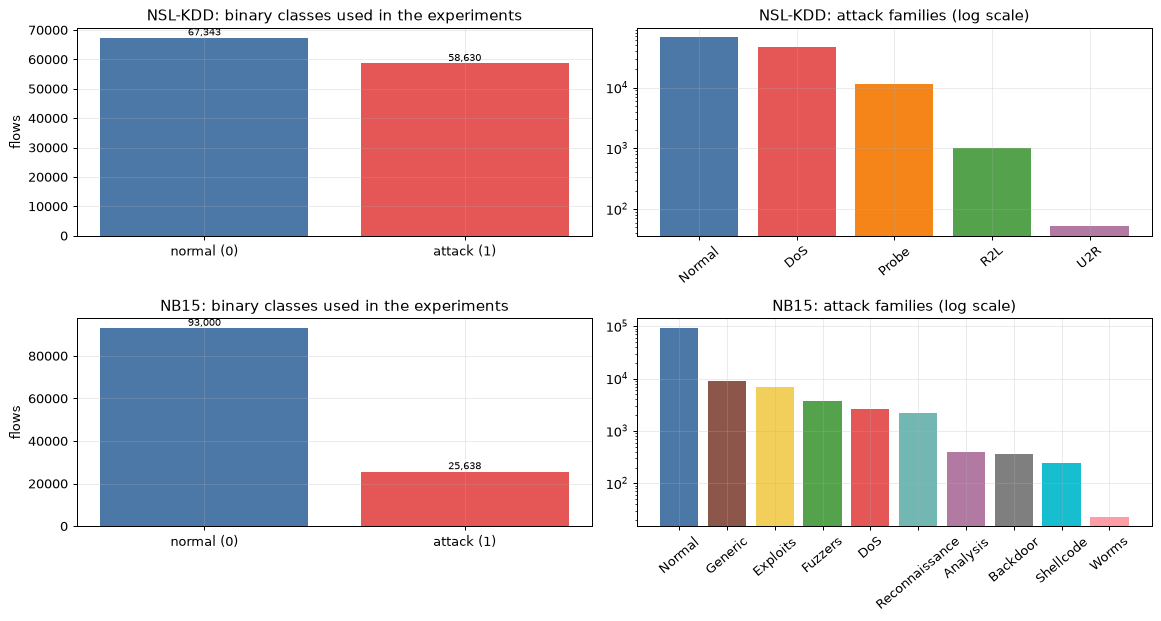

In [8]:
FAM_COLORS = {"Normal": "#4c78a8", "DoS": "#e45756", "Probe": "#f58518", "R2L": "#54a24b", "U2R": "#b279a2",
              "Generic": "#8c564b", "Exploits": "#f2cf5b", "Fuzzers": "#54a24b", "Reconnaissance": "#72b7b2",
              "Analysis": "#b279a2", "Backdoor": "#7f7f7f", "Shellcode": "#17becf", "Worms": "#ff9da6"}
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for r, (n, d) in enumerate(DS.items()):
    b = pd.Series(d["y"]).map({0: "normal (0)", 1: "attack (1)"}).value_counts()
    ax[r, 0].bar(b.index, b.values, color=["#4c78a8", "#e45756"][:len(b)])
    for i, v in enumerate(b.values): ax[r, 0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
    ax[r, 0].set_title(f"{n}: binary classes used in the experiments"); ax[r, 0].set_ylabel("flows")
    f = pd.Series(d["fam"]).value_counts()
    ax[r, 1].bar(f.index, f.values, color=[FAM_COLORS.get(k, "gray") for k in f.index]); ax[r, 1].set_yscale("log")
    ax[r, 1].set_title(f"{n}: attack families (log scale)"); ax[r, 1].tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

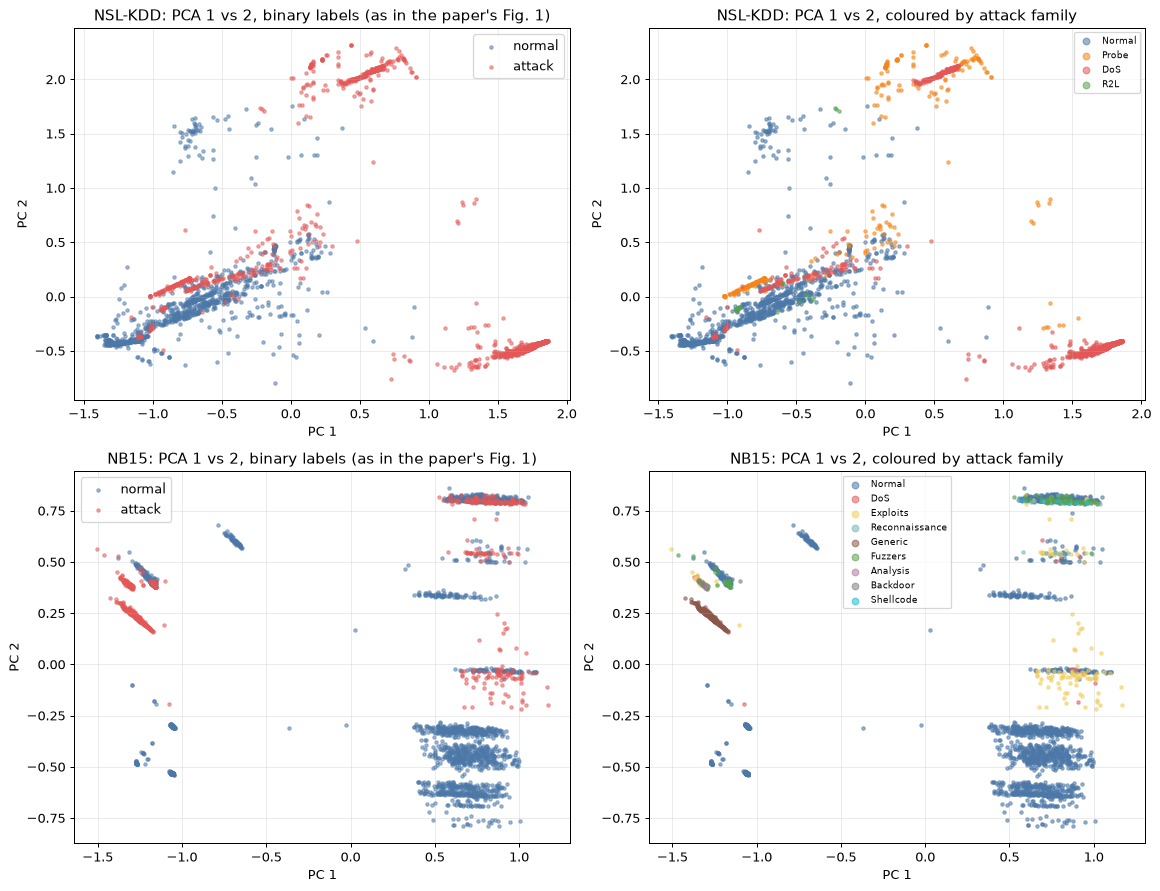

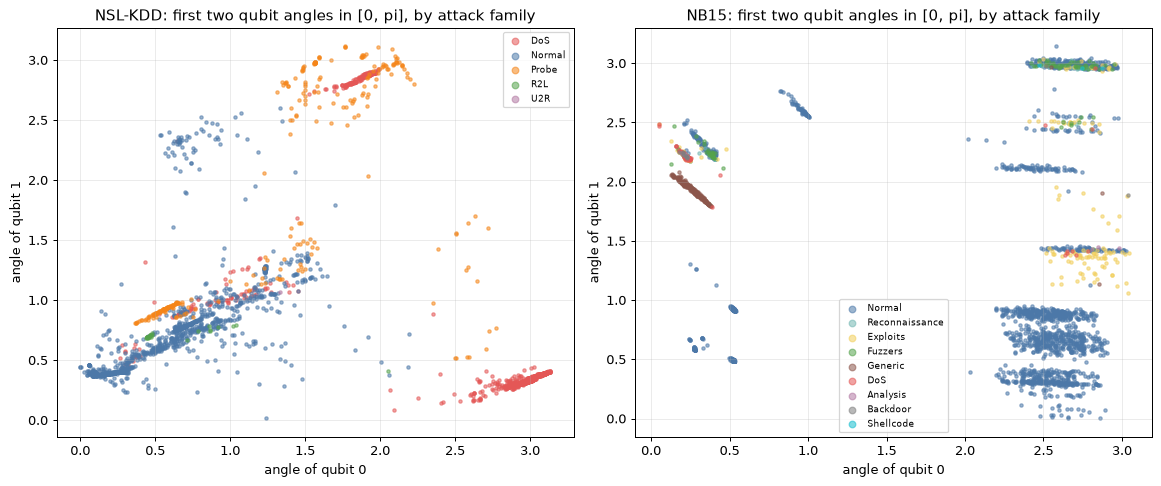

In [9]:
# Figure A: raw PCA coordinates (PCA fitted on the fit pool) of real flows, coloured by ground truth.
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
for r, (n, d) in enumerate(DS.items()):
    idx = rng.choice(d["fit_idx"], size=min(3000, len(d["fit_idx"])), replace=False)
    P = d["pca"].transform(d["X"][idx])[:, :2]
    for lab, nm, col in [(0, "normal", "#4c78a8"), (1, "attack", "#e45756")]:
        m = d["y"][idx] == lab; ax[r, 0].scatter(P[m, 0], P[m, 1], s=7, alpha=0.5, c=col, label=nm)
    ax[r, 0].set_title(f"{n}: PCA 1 vs 2, binary labels (as in the paper's Fig. 1)"); ax[r, 0].legend()
    for fam_name in pd.unique(d["fam"][idx]):
        m = d["fam"][idx] == fam_name; ax[r, 1].scatter(P[m, 0], P[m, 1], s=7, alpha=0.55, c=FAM_COLORS.get(fam_name, "gray"), label=fam_name)
    ax[r, 1].set_title(f"{n}: PCA 1 vs 2, coloured by attack family"); ax[r, 1].legend(markerscale=2, fontsize=7)
    for a in ax[r]: a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
plt.tight_layout(); plt.show()

# Figure B: the same flows after scaling the PCA outputs to [0, pi] (the angles the circuit receives; scaler fitted on the fit pool).
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for k, (n, d) in enumerate(DS.items()):
    sc = MinMaxScaler((0, np.pi)).fit(d["F"]["PCA"][d["fit_idx"]])
    idx = rng.choice(d["fit_idx"], size=min(3000, len(d["fit_idx"])), replace=False)
    A = np.clip(sc.transform(d["F"]["PCA"][idx]), 0, np.pi)
    for fam_name in pd.unique(d["fam"][idx]):
        m = d["fam"][idx] == fam_name; ax[k].scatter(A[m, 0], A[m, 1], s=7, alpha=0.55, c=FAM_COLORS.get(fam_name, "gray"), label=fam_name)
    ax[k].set_title(f"{n}: first two qubit angles in [0, pi], by attack family"); ax[k].set_xlabel("angle of qubit 0"); ax[k].set_ylabel("angle of qubit 1"); ax[k].legend(markerscale=2, fontsize=7)
plt.tight_layout(); plt.show()

**Reading the plots.** As in the paper's Fig. 1, normal and attack flows overlap strongly in the first two PCA coordinates. The family colouring shows why: DoS and probe flows form compact clusters, whereas R2L/U2R (NSL-KDD) and exploits/fuzzers (NB15) hide inside the normal cloud. No quantum model can separate what the 4 retained features do not separate.

## 3. Feature fusion: PCA, basic autoencoder (BE), variational autoencoder (VAE)

The paper reduces 41 (NSL-KDD) or 39 (NB15 here) features to **4**, one per qubit. PCA is already fitted. The autoencoders have an intermediate layer of **16 neurons** and a bottleneck of **4 neurons**, trained for **72 epochs with batches of 200**. The 4 bottleneck values (for the VAE the mean of the latent Gaussian) are the new features.

*Information loss.* The paper reports reconstruction errors on NSL-KDD of 0.0059 (BE), 0.0051 (VAE) and 0.008 (PCA). They are measured here on 5,000 flows of the extraction pool that no transform has seen.

autoencoders trained in 677 s


method,BE,VAE,PCA
dataset,,,
NB15,0.0019,0.0014,0.0085
NSL-KDD,0.0052,0.0027,0.0119


Paper (NSL-KDD): BE 0.0059, VAE 0.0051, PCA 0.008


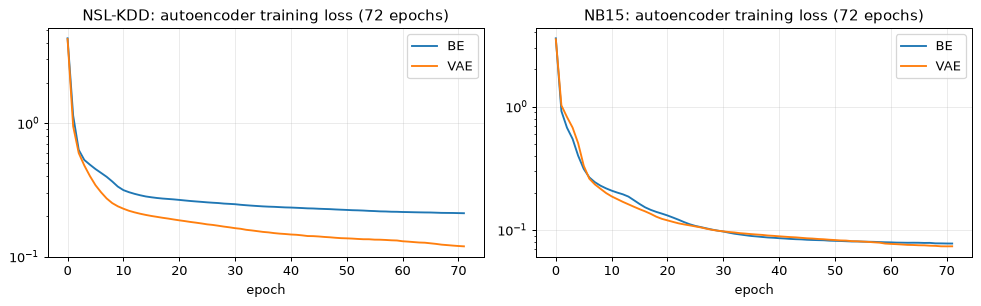

In [10]:
class AutoEncoder(nn.Module):
    def __init__(self, d, vae=False):
        super().__init__()
        self.vae = vae
        self.enc = nn.Sequential(nn.Linear(d, AE_HIDDEN), nn.ReLU())
        self.mu = nn.Linear(AE_HIDDEN, N_QUBITS)
        self.logvar = nn.Linear(AE_HIDDEN, N_QUBITS) if vae else None
        self.dec = nn.Sequential(nn.Linear(N_QUBITS, AE_HIDDEN), nn.ReLU(), nn.Linear(AE_HIDDEN, d), nn.Sigmoid())
    def encode(self, x):
        h = self.enc(x); return self.mu(h), (self.logvar(h) if self.vae else None)
    def forward(self, x):
        mu, lv = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * lv) if self.vae else mu
        return self.dec(z), mu, lv

def train_ae(Xfit, vae, seed):
    torch.manual_seed(seed)
    model = AutoEncoder(Xfit.shape[1], vae); opt = torch.optim.Adam(model.parameters(), lr=AE_LR)
    X = torch.tensor(Xfit, dtype=torch.float32); n = len(X); hist = []
    g = torch.Generator().manual_seed(seed)
    for ep in range(AE_EPOCHS):
        perm = torch.randperm(n, generator=g); tot = 0.0
        for i in range(0, n, AE_BATCH):
            xb = X[perm[i:i + AE_BATCH]]
            rec, mu, lv = model(xb)
            loss = F_.mse_loss(rec, xb, reduction="sum") / len(xb)
            if vae: loss = loss + BETA_KL * (-0.5 * torch.sum(1 + lv - mu.pow(2) - lv.exp())) / len(xb)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(xb)
        hist.append(tot / n)
    model.eval(); return model, hist

def encode_all(model, X):
    with torch.no_grad(): return model.encode(torch.tensor(X, dtype=torch.float32))[0].numpy()

t0 = time.time(); fusion_report = []
for k, (n, d) in enumerate(DS.items()):
    Xfit = d["X"][d["fit_idx"]]
    held = np.random.default_rng(SEED).choice(d["ext_idx"], size=5000, replace=False)
    d["hist"] = {}
    for method, vae in [("BE", False), ("VAE", True)]:
        model, d["hist"][method] = train_ae(Xfit, vae, SEED + k)
        d["F"][method] = encode_all(model, d["X"])
        with torch.no_grad(): mse = F_.mse_loss(model.dec(torch.tensor(encode_all(model, d["X"][held]))), torch.tensor(d["X"][held], dtype=torch.float32)).item()
        fusion_report.append((n, method, mse)); d[method + "_model"] = model
    rec = d["pca"].inverse_transform(d["F"]["PCA"][held]); fusion_report.append((n, "PCA", float(np.mean((rec - d["X"][held]) ** 2))))
    # extraction-pool views used by every experiment below
    d["Fe"] = {m: d["F"][m][d["ext_idx"]] for m in d["F"]}; d["ye"] = d["y"][d["ext_idx"]]; d["fame"] = d["fam"][d["ext_idx"]]
print(f"autoencoders trained in {time.time()-t0:.0f} s")
fusion_df = pd.DataFrame(fusion_report, columns=["dataset", "method", "reconstruction MSE (held-out flows)"]).pivot(index="dataset", columns="method", values="reconstruction MSE (held-out flows)")[["BE", "VAE", "PCA"]]
display(fusion_df.round(4))
print("Paper (NSL-KDD): BE 0.0059, VAE 0.0051, PCA 0.008")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, (n, d) in zip(ax, DS.items()):
    for m, h in d["hist"].items(): a.plot(h, label=m)
    a.set_yscale("log"); a.set_title(f"{n}: autoencoder training loss ({AE_EPOCHS} epochs)"); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 4. The quantum feature map and the quantum kernel

The paper's `ZZFeatureMap` (Eq. 1) applies Hadamards, then a data-dependent diagonal unitary `U(x)` made of single-qubit phases `P(2 x_i)` and two-qubit `ZZ` interactions `exp(i 2 (pi - x_i)(pi - x_j) Z_i Z_j)`, and repeats this twice. The QSVM kernel is the state overlap `K(x, y) = |<phi(x)|phi(y)>|^2`; the classical SVM then works on the `M x M` matrix.

Running about a thousand experiments through a shot-based `AerSimulator` would take hours, so the main loop uses an **exact NumPy statevector** implementation of the *same* circuit. The next cells prove, on random inputs, that it equals (a) Qiskit's own statevector, (b) Qiskit's `FidelityStatevectorKernel` used with `QSVC`, and (c) a shot-based `AerSimulator` compute-uncompute run.

In [11]:
_H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
_HN = _H1
for _ in range(N_QUBITS - 1): _HN = np.kron(_HN, _H1)
_BITS = ((np.arange(2 ** N_QUBITS)[:, None] >> np.arange(N_QUBITS)[None, :]) & 1).astype(float)     # qubit i = bit i (Qiskit little endian)
_PAIRS = list(itertools.combinations(range(N_QUBITS), 2)) if ENTANGLEMENT == "full" else [(i, i + 1) for i in range(N_QUBITS - 1)]

def zz_states(X, reps=FM_REPS):
    """Statevectors of zz_feature_map(n, reps, entanglement)(x) for every row of X (angles in radians), NumPy implementation."""
    X = np.atleast_2d(X)
    phase = 2.0 * (X @ _BITS.T)                                              # P(2 x_i) on every qubit
    for i, j in _PAIRS:                                                     # CX - P(2 (pi-x_i)(pi-x_j)) - CX  = phase on b_i xor b_j
        phase += 2.0 * (np.pi - X[:, [i]]) * (np.pi - X[:, [j]]) * np.abs(_BITS[:, i] - _BITS[:, j])[None, :]
    ph = np.exp(1j * phase)
    psi = np.zeros((len(X), 2 ** N_QUBITS), complex); psi[:, 0] = 1
    for _ in range(reps): psi = (psi @ _HN.T) * ph
    return psi

def q_kernel(A, B=None):
    A = zz_states(A); B = A if B is None else zz_states(B)
    return np.abs(A @ B.conj().T) ** 2

# --- equivalence check 1: against Qiskit's own statevector
fm = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement=ENTANGLEMENT)
rng = np.random.default_rng(SEED); Xchk = rng.uniform(0, np.pi, size=(12, N_QUBITS))
sv = np.array([Statevector(fm.assign_parameters(x)).data for x in Xchk])
assert np.allclose(zz_states(Xchk), sv, atol=1e-10), "NumPy statevectors differ from Qiskit"
print("NumPy ZZ-feature-map statevectors == Qiskit statevectors (12 random points, atol 1e-10)")

NumPy ZZ-feature-map statevectors == Qiskit statevectors (12 random points, atol 1e-10)


## Quantum Circuit Architecture

Two gate-based models are executed in this notebook, so two architectures are drawn.

1. **QSVM kernel circuit** (Qiskit). For two flows `x` and `y` the kernel entry is estimated by running `ZZFeatureMap(x)` followed by the inverse of `ZZFeatureMap(y)` and measuring all qubits; the probability of the all-zero outcome is `K(x, y)`. The circuit below is the one that is transpiled to the gate set `{h, p, cx}` and run on the `AerSimulator`. It has **no trainable parameters** (the learning is done by the classical SVM).
2. **VQC** (PennyLane): amplitude embedding of the 4 features on 2 qubits and trainable `StronglyEntanglingLayers`; the drawing comes from the QNode that is trained in section 11.

Assumptions where the paper omits details: ZZ entanglement `full` (all 6 qubit pairs), `reps = 2`, features multiplied by pi before entering the circuit; the paper's "depth 2" refers to the two repetitions of the feature-map block, the actual gate depth is printed below.

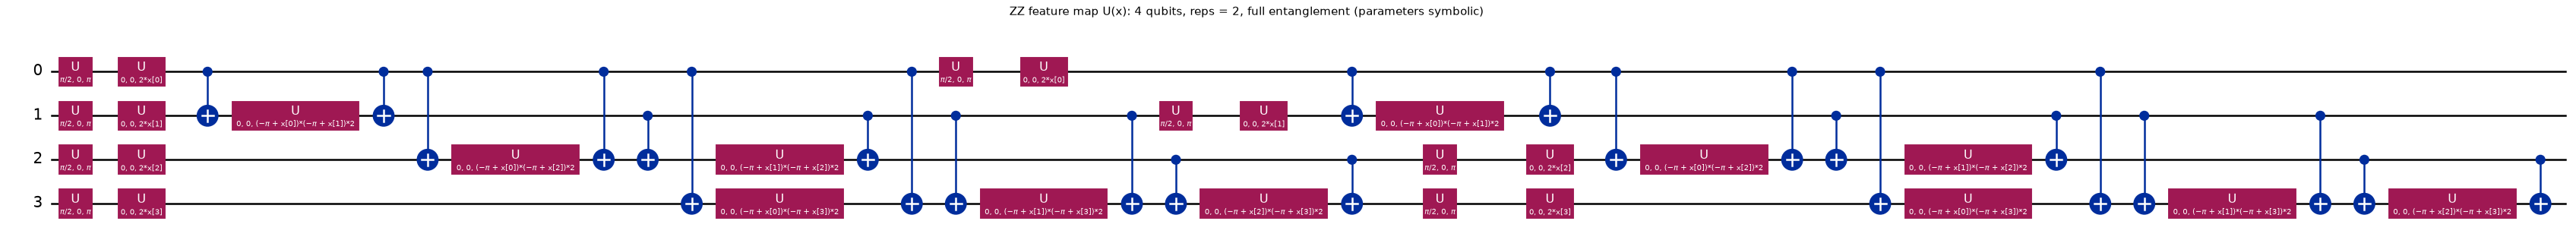

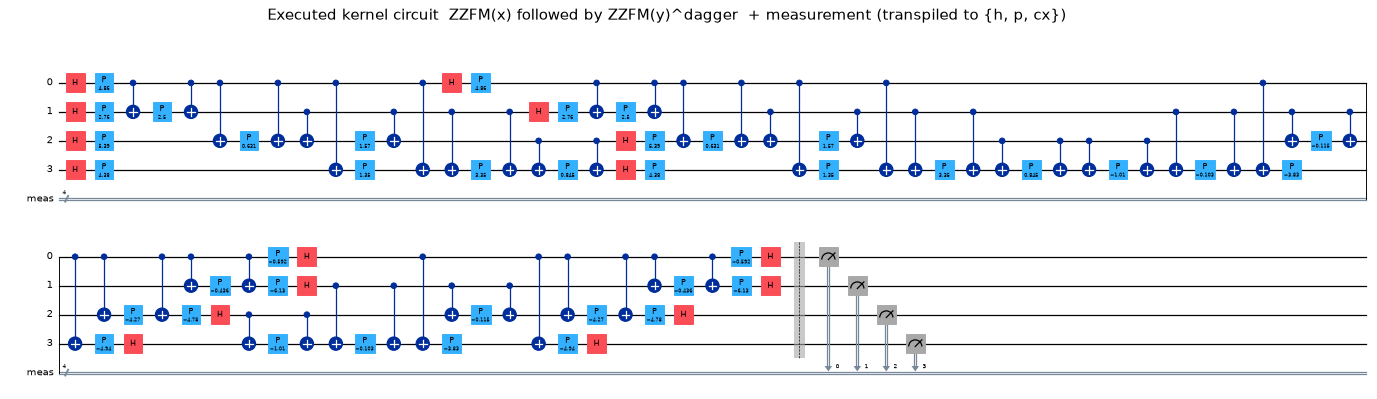

QSVM kernel circuit:
  qubits                 : 4
  depth (feature map only, decomposed to h/p/cx): 31 | feature-map repetitions (paper's 'depth 2'): 2
  depth (full kernel circuit as executed): 63 | gate counts: {'cx': 48, 'p': 40, 'h': 16, 'measure': 4, 'barrier': 1}
  trainable parameters   : 0 (data parameters: 4 per feature-map copy)


In [12]:
x_demo, y_demo = Xchk[0], Xchk[1]
kern_circ = fm.assign_parameters(x_demo).compose(fm.assign_parameters(y_demo).inverse())
kern_circ.measure_all()
aer = AerSimulator(seed_simulator=SEED)
exec_circ = transpile(kern_circ, aer, basis_gates=["h", "p", "cx"], optimization_level=0, seed_transpiler=SEED)

fig = fm.decompose().draw("mpl", fold=60)
fig.suptitle("ZZ feature map U(x): 4 qubits, reps = 2, full entanglement (parameters symbolic)", y=1.0); display(fig); plt.close(fig)
fig = exec_circ.draw("mpl", fold=45, scale=0.5)
fig.suptitle("Executed kernel circuit  ZZFM(x) followed by ZZFM(y)^dagger  + measurement (transpiled to {h, p, cx})", y=1.0); display(fig); plt.close(fig)

print("QSVM kernel circuit:")
print("  qubits                 :", exec_circ.num_qubits)
print("  depth (feature map only, decomposed to h/p/cx):", transpile(fm, basis_gates=["h", "p", "cx"], optimization_level=0).depth(),
      "| feature-map repetitions (paper's 'depth 2'):", FM_REPS)
print("  depth (full kernel circuit as executed):", exec_circ.depth(), "| gate counts:", dict(exec_circ.count_ops()))
print("  trainable parameters   :", 0, "(data parameters:", fm.num_parameters, "per feature-map copy)")

In [13]:
# --- equivalence checks 2 and 3: Qiskit FidelityStatevectorKernel + QSVC, and a shot-based AerSimulator run
Xa = rng.uniform(0, np.pi, size=(8, N_QUBITS)); Xb = rng.uniform(0, np.pi, size=(6, N_QUBITS))
K_numpy = q_kernel(Xa, Xb)
K_qiskit = FidelityStatevectorKernel(feature_map=fm).evaluate(Xa, Xb)
assert np.allclose(K_numpy, K_qiskit, atol=1e-9); print("NumPy kernel == Qiskit FidelityStatevectorKernel (8 x 6 entries)")

def aer_kernel_entry(x, y, shots=SHOTS):
    c = fm.assign_parameters(x).compose(fm.assign_parameters(y).inverse()); c.measure_all()
    c = transpile(c, aer, basis_gates=["h", "p", "cx"], optimization_level=0, seed_transpiler=SEED)
    counts = aer.run(c, shots=shots, seed_simulator=SEED).result().get_counts()
    return counts.get("0" * N_QUBITS, 0) / shots
K_aer = np.array([[aer_kernel_entry(a, b) for b in Xb] for a in Xa])
print(f"AerSimulator ({SHOTS} shots) vs exact: max |difference| = {np.abs(K_aer - K_numpy).max():.4f}  (binomial standard error <= {0.5/np.sqrt(SHOTS):.4f})")
assert np.abs(K_aer - K_numpy).max() < 5 * 0.5 / np.sqrt(SHOTS)

# QSVC (Qiskit) and SVC(precomputed) on the same tiny problem give the same predictions
Xt = rng.uniform(0, np.pi, size=(40, N_QUBITS)); yt = (np.sin(Xt[:, 0]) + Xt[:, 1] > 2.2).astype(int); Xs_ = rng.uniform(0, np.pi, size=(20, N_QUBITS))
qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=fm), C=QSVM_C).fit(Xt, yt)
svc = SVC(kernel="precomputed", C=QSVM_C).fit(q_kernel(Xt), yt)
assert (qsvc.predict(Xs_) == svc.predict(q_kernel(Xs_, Xt))).all(); print("QSVC (Qiskit) predictions == SVC(precomputed) on the NumPy kernel")

NumPy kernel == Qiskit FidelityStatevectorKernel (8 x 6 entries)


AerSimulator (4096 shots) vs exact: max |difference| = 0.0079  (binomial standard error <= 0.0078)


QSVC (Qiskit) predictions == SVC(precomputed) on the NumPy kernel


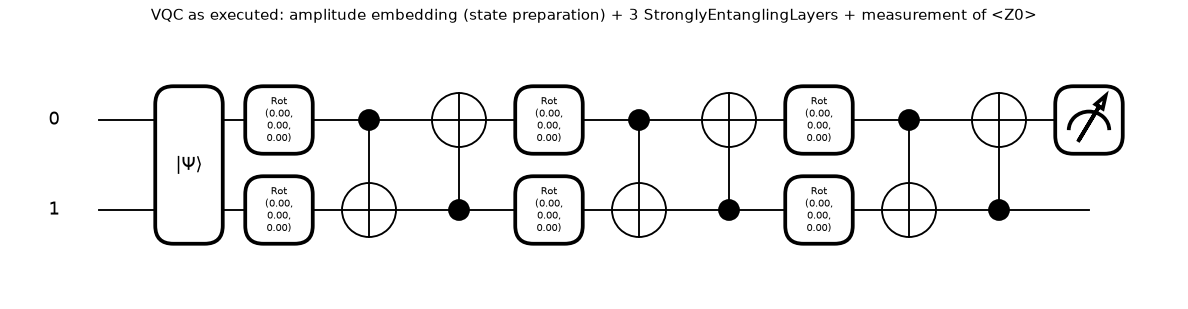

0: ─╭|Ψ⟩─╭StronglyEntanglingLayers(M0)─┤  <Z>
1: ─╰|Ψ⟩─╰StronglyEntanglingLayers(M0)─┤     

M0 = 
[[[0. 0. 0.]
  [0. 0. 0.]]

 [[0. 0. 0.]
  [0. 0. 0.]]

 [[0. 0. 0.]
  [0. 0. 0.]]]
VQC: qubits 2 | trainable parameters 18 | depth (device level) 10


In [14]:
# Architecture 2: the PennyLane VQC (trained in section 11). The QNode defined here is the one that is trained.
from pennylane import numpy as pnp
VQC_QUBITS, VQC_LAYERS = 2, 3                       # CHOICE: 4 amplitudes need 2 qubits
dev = qml.device("default.qubit", wires=VQC_QUBITS)

@qml.qnode(dev, interface="autograd", diff_method="backprop")
def vqc(weights, x):
    qml.AmplitudeEmbedding(x, wires=range(VQC_QUBITS), normalize=True)        # CHOICE: amplitude encoding as in the paper
    qml.StronglyEntanglingLayers(weights, wires=range(VQC_QUBITS))            # CHOICE: ansatz (paper gives none)
    return qml.expval(qml.PauliZ(0))

_x0 = np.array([0.3, 0.2, 0.5, 0.1]); _w0 = pnp.zeros((VQC_LAYERS, VQC_QUBITS, 3))
fig, ax = qml.draw_mpl(vqc, decimals=2, level="device")(_w0, _x0)
fig.suptitle("VQC as executed: amplitude embedding (state preparation) + 3 StronglyEntanglingLayers + measurement of <Z0>", y=1.08); plt.show()
print(qml.draw(vqc, level="top")(_w0, _x0))
print("VQC: qubits", VQC_QUBITS, "| trainable parameters", int(np.prod(_w0.shape)), "| depth (device level)", qml.specs(vqc, level="device")(_w0, _x0)["resources"].depth)

## 5. Experiment engine

One *extraction* = draw `Z` points from the extraction pool (natural class mix, or a prescribed share `gamma1` of attacks), split them `(alpha, beta)` with stratification, scale the 4 fused features with a `MinMaxScaler` **fitted on the training split only** (test values clipped to [0, 1]), and train:

* **QSVM** (exact ZZ-kernel + `SVC(precomputed)`),
* **SVM-poly** (the paper's classical baseline kernel) and **RF** / **SVM-rbf** (extra baselines) on exactly the same scaled inputs.

The same extraction (same random points) is used for BE, VAE and PCA at a given `(Z, gamma, repetition)`, so the comparison between fusion methods is paired.

In [15]:
def draw_extraction(d, Z, alpha, gamma, rep, tag=0):
    """Indices (into the extraction pool) of a random Z-point draw and its stratified train/test split."""
    rng = np.random.default_rng([SEED, tag, rep, Z, int(round(alpha * 100)), int(round((gamma or 0) * 100))])
    y = d["ye"]
    if gamma is None:
        idx = rng.choice(len(y), size=Z, replace=False)
    else:
        na = int(round(gamma * Z))
        idx = np.concatenate([rng.choice(np.flatnonzero(y == 1), size=na, replace=False), rng.choice(np.flatnonzero(y == 0), size=Z - na, replace=False)])
    tr, te = train_test_split(idx, train_size=alpha, stratify=y[idx], random_state=int(rng.integers(1 << 30)))
    return tr, te

def fit_eval(Fm, y, tr, te, models=("qsvm", "svm", "rf", "svm_rbf")):
    sc = MinMaxScaler().fit(Fm[tr]); Xtr = sc.transform(Fm[tr]); Xte = np.clip(sc.transform(Fm[te]), 0, 1); ytr, yte = y[tr], y[te]
    out = {}
    if "qsvm" in models:
        t0 = time.perf_counter(); Ktr = q_kernel(ANGLE_SCALE * Xtr); clf = SVC(kernel="precomputed", C=QSVM_C).fit(Ktr, ytr); t1 = time.perf_counter()
        Kte = q_kernel(ANGLE_SCALE * Xte, ANGLE_SCALE * Xtr); p = clf.predict(Kte); t2 = time.perf_counter()
        out.update(acc_qsvm=accuracy_score(yte, p), bacc_qsvm=balanced_accuracy_score(yte, p), t_inf_qsvm=t2 - t1, t_fit_qsvm=t1 - t0, pred_qsvm=p)
    base = {"svm": SVC(kernel="poly", degree=3, C=1.0), "svm_rbf": SVC(kernel="rbf", C=1.0), "rf": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1)}
    for k in models:
        if k in base:
            t0 = time.perf_counter(); m = base[k].fit(Xtr, ytr); t1 = time.perf_counter(); p = m.predict(Xte); t2 = time.perf_counter()
            out.update({f"acc_{k}": accuracy_score(yte, p), f"bacc_{k}": balanced_accuracy_score(yte, p), f"t_inf_{k}": t2 - t1})
    return out

def sweep(dname, methods, Zs, alphas, gammas, models=("qsvm", "svm", "rf", "svm_rbf"), n_reps=None, keep_idx=False):
    d = DS[dname]; rows = []
    for Z, alpha, gamma, rep in itertools.product(Zs, alphas, gammas, range(n_reps or N_REPS)):
        tr, te = draw_extraction(d, Z, alpha, gamma, rep)
        for m in methods:
            r = fit_eval(d["Fe"][m], d["ye"], tr, te, models); r.pop("pred_qsvm", None)
            r.update(dataset=dname, method=m, Z=Z, alpha=alpha, gamma=gamma, rep=rep)
            if keep_idx: r.update(tr=tr, te=te)
            rows.append(r)
    return pd.DataFrame(rows)

def summarize(df, by, col="acc_qsvm"):
    g = df.groupby(by)[col].agg(["mean", "std", "min", "max"]); return g
_t = draw_extraction(DS["NSL-KDD"], 150, 0.8, None, 0); r = fit_eval(DS["NSL-KDD"]["Fe"]["PCA"], DS["NSL-KDD"]["ye"], *_t)
print("smoke test (one NSL-KDD extraction, PCA):", {k: round(float(v), 3) for k, v in r.items() if k.startswith("acc_")})

smoke test (one NSL-KDD extraction, PCA): {'acc_qsvm': 0.9, 'acc_svm': 0.9, 'acc_rf': 0.9, 'acc_svm_rbf': 0.9}


## 6. Tables I and II: QSVM vs SVM with PCA, varying the split and `Z`

NSL-KDD (Table I): `Z` = 150 and 250; NB15 (Table II): `Z` = 200 and 300. The points are drawn at random from the pool with its natural class mix.

*The SVM columns.* The paper's SVM numbers are quoted from Gouveia and Correia (2020), where the SVM was trained on the **whole dataset**. Here **SVM (large)** is a polynomial-kernel SVM trained on `BIG_TRAIN` random flows of the pool (the paper's setting, scaled down) and tested on `BIG_TEST` unseen flows; **SVM (same Z)** is trained on exactly the same `Z` points as the QSVM, which is the fair comparison.

In [16]:
def big_svm(dname, method="PCA", seed_tag=7):
    d = DS[dname]; rng = np.random.default_rng([SEED, seed_tag]); n = len(d["ye"])
    idx = rng.permutation(n)[: BIG_TRAIN + BIG_TEST]; tr, te = idx[:BIG_TRAIN], idx[BIG_TRAIN:]
    sc = MinMaxScaler().fit(d["Fe"][method][tr]); Xtr = sc.transform(d["Fe"][method][tr]); Xte = np.clip(sc.transform(d["Fe"][method][te]), 0, 1)
    t0 = time.perf_counter(); m = SVC(kernel="poly", degree=3, C=1.0).fit(Xtr, d["ye"][tr]); t1 = time.perf_counter(); p = m.predict(Xte); t2 = time.perf_counter()
    return dict(acc=accuracy_score(d["ye"][te], p), bacc=balanced_accuracy_score(d["ye"][te], p), t_fit=t1 - t0, t_inf=t2 - t1, n_test=len(te))

SPLITS = [2 / 3, 0.75, 0.80]
t0 = time.time()
big = {n: big_svm(n) for n in DS}
print({n: {k: round(v, 3) for k, v in b.items()} for n, b in big.items()})
T1 = sweep("NSL-KDD", ["PCA"], [150, 250], SPLITS, [None])
T2 = sweep("NB15", ["PCA"], [200, 300], SPLITS[1:], [None])
print(f"Tables I/II computed in {time.time()-t0:.0f} s")

def table12(T, big_acc, Zs, paper_svm):
    rows = []
    for a in sorted(T.alpha.unique()):
        s = T[T.alpha == a]; row = {"(alpha, beta)": f"({a*100:.1f}%, {100-a*100:.1f}%)", "SVM paper": paper_svm.get(round(a, 2), "N/A"), "SVM (large) here": round(big_acc, 3)}
        row["SVM same Z"] = " / ".join(f"{s[s.Z==z].acc_svm.mean():.2f}" for z in Zs); row["RF same Z"] = " / ".join(f"{s[s.Z==z].acc_rf.mean():.2f}" for z in Zs)
        for z in Zs: row[f"QSVM Z={z}"] = f"{s[s.Z==z].acc_qsvm.mean():.3f} +- {s[s.Z==z].acc_qsvm.std():.3f}"
        rows.append(row)
    return pd.DataFrame(rows)
print("TABLE I  (NSL-KDD, PCA)  paper: QSVM Z=150: 0.85/0.87/0.90, Z=250: 0.88/0.90/0.92; SVM 0.80"); display(table12(T1, big["NSL-KDD"]["acc"], [150, 250], {0.67: "0.80 [9]"}))
print("TABLE II (NB15, PCA)     paper: QSVM Z=200: 0.68/0.71, Z=300: 0.70/0.73; SVM 0.60")
display(table12(T2, big["NB15"]["acc"], [200, 300], {0.75: "0.60 [9]"}))
for n in DS: print(f"{n}: majority-class accuracy of the pool = {max(DS[n]['ye'].mean(), 1-DS[n]['ye'].mean()):.3f}")
print("Balanced accuracy of QSVM (NB15, 80/20):", T2[T2.alpha == 0.8].groupby("Z").bacc_qsvm.mean().round(3).to_dict())

{'NSL-KDD': {'acc': 0.939, 'bacc': 0.938, 't_fit': 25.554, 't_inf': 1.907, 'n_test': 10000}, 'NB15': {'acc': 0.923, 'bacc': 0.839, 't_fit': 20.979, 't_inf': 2.454, 'n_test': 10000}}


Tables I/II computed in 270 s
TABLE I  (NSL-KDD, PCA)  paper: QSVM Z=150: 0.85/0.87/0.90, Z=250: 0.88/0.90/0.92; SVM 0.80


,"(alpha, beta)",SVM paper,SVM (large) here,SVM same Z,RF same Z,QSVM Z=150,QSVM Z=250
0,"(66.7%, 33.3%)",0.80 [9],0.939,0.92 / 0.91,0.95 / 0.94,0.907 +- 0.037,0.887 +- 0.036
1,"(75.0%, 25.0%)",N/A,0.939,0.91 / 0.91,0.93 / 0.94,0.883 +- 0.056,0.893 +- 0.037
2,"(80.0%, 20.0%)",N/A,0.939,0.91 / 0.90,0.94 / 0.92,0.883 +- 0.048,0.891 +- 0.033


TABLE II (NB15, PCA)     paper: QSVM Z=200: 0.68/0.71, Z=300: 0.70/0.73; SVM 0.60


,"(alpha, beta)",SVM paper,SVM (large) here,SVM same Z,RF same Z,QSVM Z=200,QSVM Z=300
0,"(75.0%, 25.0%)",0.60 [9],0.923,0.89 / 0.90,0.92 / 0.92,0.892 +- 0.035,0.907 +- 0.040
1,"(80.0%, 20.0%)",N/A,0.923,0.89 / 0.90,0.91 / 0.92,0.879 +- 0.045,0.912 +- 0.033


NSL-KDD: majority-class accuracy of the pool = 0.535
NB15: majority-class accuracy of the pool = 0.784
Balanced accuracy of QSVM (NB15, 80/20): {200: 0.75, 300: 0.819}


## 7. Table III and Figures 2-3: fusion method x class mix (NSL-KDD)

`(gamma1, gamma2)` is the share of attack and normal flows among the `Z` points. Split fixed at `(80%, 20%)` as in the paper. For each of BE, VAE and PCA we report the mean over the extractions and draw the accuracy distributions (the paper's Figs. 2 and 3).

Table III computed in 20 s
TABLE III  (NSL-KDD, QSVM, mean accuracy over the extractions; paper value in brackets)


,BE Z=150,BE Z=250,VAE Z=150,VAE Z=250,PCA Z=150,PCA Z=250
"(60%, 40%)",0.87 (paper 0.88),0.88 (paper 0.90),0.87 (paper 0.91),0.86 (paper 0.92),0.87 (paper 0.87),0.89 (paper 0.88)
"(50%, 50%)",0.91 (paper 0.90),0.91 (paper 0.92),0.87 (paper 0.93),0.89 (paper 0.94),0.88 (paper 0.90),0.89 (paper 0.92)
"(55%, 45%)",0.87 (paper 0.94),0.89 (paper 0.95),0.86 (paper 0.95),0.89 (paper 0.96),0.86 (paper 0.92),0.89 (paper 0.94)


SVM-poly on the same Z points (mean): {'BE': 0.942, 'PCA': 0.915, 'VAE': 0.923}


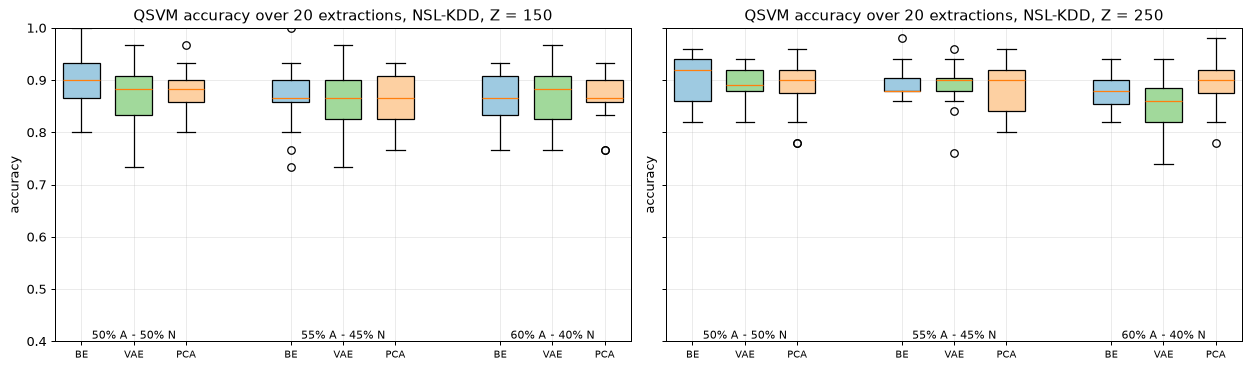

In [17]:
GAMMAS = [0.60, 0.50, 0.55]
t0 = time.time()
T3 = sweep("NSL-KDD", ["BE", "VAE", "PCA"], [150, 250], [0.8], GAMMAS, models=("qsvm", "svm"), keep_idx=True)
print(f"Table III computed in {time.time()-t0:.0f} s")
paper3 = {(0.60, "BE", 150): .88, (0.60, "BE", 250): .90, (0.60, "VAE", 150): .91, (0.60, "VAE", 250): .92, (0.60, "PCA", 150): .87, (0.60, "PCA", 250): .88,
          (0.50, "BE", 150): .90, (0.50, "BE", 250): .92, (0.50, "VAE", 150): .93, (0.50, "VAE", 250): .94, (0.50, "PCA", 150): .90, (0.50, "PCA", 250): .92,
          (0.55, "BE", 150): .94, (0.55, "BE", 250): .95, (0.55, "VAE", 150): .95, (0.55, "VAE", 250): .96, (0.55, "PCA", 150): .92, (0.55, "PCA", 250): .94}
m3 = T3.groupby(["gamma", "method", "Z"]).acc_qsvm.mean().unstack(["method", "Z"])
tab = pd.DataFrame({f"{m} Z={z}": [f"{m3.loc[g, (m, z)]:.2f} (paper {paper3[(g, m, z)]:.2f})" for g in GAMMAS] for m in ["BE", "VAE", "PCA"] for z in [150, 250]},
                   index=[f"({int(g*100)}%, {100-int(g*100)}%)" for g in GAMMAS])
print("TABLE III  (NSL-KDD, QSVM, mean accuracy over the extractions; paper value in brackets)"); display(tab)
print("SVM-poly on the same Z points (mean):", T3.groupby("method").acc_svm.mean().round(3).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for a, z in zip(ax, [150, 250]):
    data, labels, pos = [], [], []
    for gi, g in enumerate([0.50, 0.55, 0.60]):
        for mi, m in enumerate(["BE", "VAE", "PCA"]):
            data.append(T3[(T3.Z == z) & (T3.gamma == g) & (T3.method == m)].acc_qsvm.values); labels.append(m); pos.append(gi * 4 + mi)
    bp = a.boxplot(data, positions=pos, widths=0.7, patch_artist=True)
    for patch, m in zip(bp["boxes"], labels): patch.set_facecolor({"BE": "#9ecae1", "VAE": "#a1d99b", "PCA": "#fdd0a2"}[m])
    a.set_xticks(pos); a.set_xticklabels(labels, fontsize=8)
    for gi, g in enumerate([50, 55, 60]): a.text(gi * 4 + 1, 0.405, f"{g}% A - {100-g}% N", ha="center", fontsize=9)
    a.set_title(f"QSVM accuracy over {N_REPS} extractions, NSL-KDD, Z = {z}"); a.set_ylim(0.4, 1.0); a.set_ylabel("accuracy")
plt.tight_layout(); plt.show()

## 8. Table IV and Figures 4-5: the outlier case

The paper takes the worst draw (BE, 50%/50%, `Z` = 150, accuracy 0.70), shows that its training points are not linearly separable, and then adds 5% or 10% extra attack points taken from the rest of the dataset: *intra-class* points are those closest to the existing attack neighbourhood, *inter-class* points are those closest to the normal neighbourhood (the overlap region).

Here the same procedure is applied to the **worst `N_OUTLIERS` draws** of that setting (a single draw is too noisy to conclude from). A **control** adds the same number of *random* attack points; because a worst draw tends to improve by chance on any re-evaluation (regression to the mean), the control tells how much of the paper's "+13 points" is due to the chosen points. The test points are never changed.

TABLE IV (NSL-KDD, BE, 50%/50%, Z=150): worst draws, then extra attack points added to their training sets


,outlier,+5% intra,+5% inter,+5% random (control),+10% intra,+10% inter,+10% random (control)
rank,,,,,,,
1,0.800,0.800,0.800,0.780,0.800,0.800,0.783
2,0.867,0.867,0.867,0.853,0.867,0.867,0.860
3,0.867,0.867,0.867,0.883,0.867,0.900,0.873
4,0.867,0.867,0.833,0.863,0.867,0.867,0.853
5,0.867,0.867,0.867,0.880,0.867,0.900,0.860
mean,0.853,0.853,0.847,0.852,0.853,0.867,0.846


Paper: outlier 0.70 | +5% intra 0.83 | +10% inter 0.50


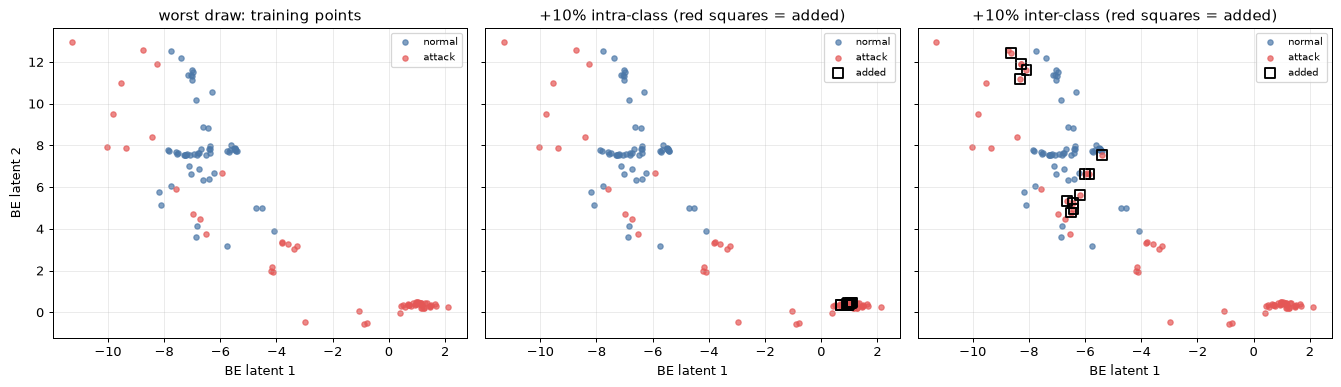

In [18]:
d = DS["NSL-KDD"]; FeBE = d["Fe"]["BE"]; ye = d["ye"]
cand = T3[(T3.method == "BE") & (T3.gamma == 0.5) & (T3.Z == 150)].sort_values("acc_qsvm").head(N_OUTLIERS)

def nearest_dist(C, ref, k=5):
    D = np.linalg.norm(C[:, None, :] - ref[None, :, :], axis=2); return np.sort(D, axis=1)[:, :k].mean(1)

def scenario(tr, te, extra, rng_):
    tr2 = np.concatenate([tr, extra]) if len(extra) else tr
    return fit_eval(FeBE, ye, tr2, te, models=("qsvm",))["acc_qsvm"], tr2

rows = []; shown = None
for rank, (_, r) in enumerate(cand.iterrows()):
    tr, te = r["tr"], r["te"]; rng_ = np.random.default_rng([SEED, 99, rank])
    used = set(tr) | set(te); pool_att = np.array([i for i in np.flatnonzero(ye == 1) if i not in used])
    cids = rng_.choice(pool_att, size=min(400, len(pool_att)), replace=False)          # candidate extra attack flows
    sc = MinMaxScaler().fit(FeBE[tr]); Ftr, Fc = sc.transform(FeBE[tr]), np.clip(sc.transform(FeBE[cids]), 0, 1)
    d_att = nearest_dist(Fc, Ftr[ye[tr] == 1]); d_nor = nearest_dist(Fc, Ftr[ye[tr] == 0])
    res = {"rank": rank + 1, "outlier": r["acc_qsvm"]}
    for frac in (0.05, 0.10):
        k = int(np.ceil(frac * len(tr)))
        res[f"+{int(frac*100)}% intra"], tr_i = scenario(tr, te, cids[np.argsort(d_att)[:k]], rng_)
        res[f"+{int(frac*100)}% inter"], tr_n = scenario(tr, te, cids[np.argsort(d_nor)[:k]], rng_)
        res[f"+{int(frac*100)}% random (control)"] = np.mean([scenario(tr, te, rng_.choice(cids, size=k, replace=False), rng_)[0] for _ in range(10)])
        if rank == 0 and frac == 0.10: shown = (tr, te, tr_i, tr_n)
    rows.append(res)
T4 = pd.DataFrame(rows).set_index("rank"); T4.loc["mean"] = T4.mean()
print("TABLE IV (NSL-KDD, BE, 50%/50%, Z=150): worst draws, then extra attack points added to their training sets"); display(T4.round(3))
print("Paper: outlier 0.70 | +5% intra 0.83 | +10% inter 0.50")

# Figs. 4-5: the training points of the worst draw (BE features 1 and 2) before and after the additions
tr, te, tr_i, tr_n = shown; rt = cand.iloc[0]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), sharex=True, sharey=True)
for a, (ttl, trs) in zip(ax, [("worst draw: training points", tr), ("+10% intra-class (red squares = added)", tr_i), ("+10% inter-class (red squares = added)", tr_n)]):
    for lab, col, nm in [(0, "#4c78a8", "normal"), (1, "#e45756", "attack")]:
        m = ye[trs] == lab; a.scatter(FeBE[trs][m, 0], FeBE[trs][m, 1], s=18, c=col, alpha=0.7, label=nm)
    if len(trs) > len(tr): a.scatter(FeBE[trs[len(tr):], 0], FeBE[trs[len(tr):], 1], s=60, marker="s", facecolors="none", edgecolors="k", linewidths=1.5, label="added")
    a.set_title(ttl); a.set_xlabel("BE latent 1"); a.legend(fontsize=8)
ax[0].set_ylabel("BE latent 2"); plt.tight_layout(); plt.show()

## 9. Table V: VAE on NB15

QSVM with VAE features on the NB15 pool, the three class mixes, `Z` = 200 and 300, split (80%, 20%).

In [19]:
T5 = sweep("NB15", ["VAE", "PCA"], [200, 300], [0.8], GAMMAS, models=("qsvm", "svm"))
p5 = {(0.60, 200): .84, (0.60, 300): .85, (0.50, 200): .85, (0.50, 300): .87, (0.55, 200): .88, (0.55, 300): .89}
m5 = T5[T5.method == "VAE"].groupby(["gamma", "Z"]).acc_qsvm.mean()
tab5 = pd.DataFrame({f"VAE Z={z}": [f"{m5.loc[(g, z)]:.2f} (paper {p5[(g, z)]:.2f})" for g in GAMMAS] for z in [200, 300]}, index=[f"({int(g*100)}%, {100-int(g*100)}%)" for g in GAMMAS])
tab5["PCA Z=300 (here)"] = [f"{T5[(T5.method=='PCA') & (T5.gamma==g) & (T5.Z==300)].acc_qsvm.mean():.2f}" for g in GAMMAS]
print("TABLE V (NB15, QSVM + VAE; paper value in brackets)"); display(tab5)
print("SVM-poly on the same Z points (VAE inputs):", T5[T5.method == "VAE"].acc_svm.mean().round(3))

TABLE V (NB15, QSVM + VAE; paper value in brackets)


,VAE Z=200,VAE Z=300,PCA Z=300 (here)
"(60%, 40%)",0.80 (paper 0.84),0.83 (paper 0.85),0.86
"(50%, 50%)",0.81 (paper 0.85),0.79 (paper 0.87),0.86
"(55%, 45%)",0.79 (paper 0.88),0.81 (paper 0.89),0.87


SVM-poly on the same Z points (VAE inputs): 0.861


## 10. Fair comparison in strongly overlapping zones (SVM vs QSVM)

The paper's closing question: is the QSVM's advantage real, or just a consequence of comparing a QSVM trained on a few hundred points with an SVM trained on the whole dataset? It trains both on *identical* points from strongly overlapping zones (100 training, 50 test, 20 repeats) and reports SVM 0.32-0.59 (0.015 s) vs QSVM 0.50-0.68 (4.11 s).

Zones are defined here as the flows (PCA features, NSL-KDD) for which at least 40% of the 15 nearest neighbours carry the opposite label. Zone membership uses labels of a scanned subset of the pool: this is a data-selection step that intentionally builds a very hard test bed, not a model fit. Because the selected flows are by construction in the minority within their neighbourhood, a below-chance accuracy is expected for any local model.

scanned 20000 flows; 636 lie in strongly overlapping zones (>= 40% opposite-class neighbours); attack share in the zone: 0.52


      acc_svm  acc_qsvm  acc_rf  t_inf_svm  t_inf_qsvm
mean    0.583     0.582   0.643     0.0029      0.0056
min     0.460     0.420   0.520     0.0006      0.0017
max     0.660     0.700   0.800     0.0074      0.0113


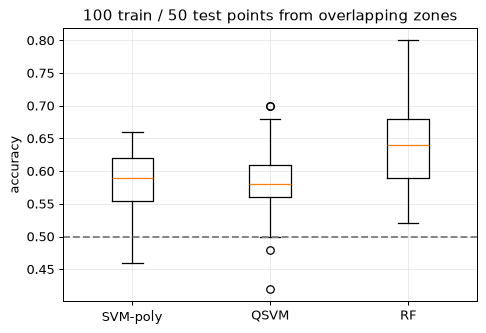

In [20]:
d = DS["NSL-KDD"]; rng = np.random.default_rng([SEED, 55])
sub = rng.choice(len(d["ye"]), size=min(OVERLAP_POOL, len(d["ye"])), replace=False)
Fo = MinMaxScaler().fit_transform(d["Fe"]["PCA"][sub]); yo = d["ye"][sub]
_, ind = NearestNeighbors(n_neighbors=16).fit(Fo).kneighbors(Fo)
other = (yo[ind[:, 1:]] != yo[:, None]).mean(1); zone = sub[other >= 0.40]
print(f"scanned {len(sub)} flows; {len(zone)} lie in strongly overlapping zones (>= 40% opposite-class neighbours); attack share in the zone: {d['ye'][zone].mean():.2f}")
rows = []
for rep in range(OVERLAP_REPS):
    r_ = np.random.default_rng([SEED, 56, rep]); idx = r_.choice(zone, size=150, replace=False)
    tr, te = train_test_split(idx, train_size=100, stratify=d["ye"][idx], random_state=int(r_.integers(1 << 30)))
    o = fit_eval(d["Fe"]["PCA"], d["ye"], tr, te, models=("qsvm", "svm", "rf")); o.pop("pred_qsvm"); rows.append(o)
OV = pd.DataFrame(rows)
print(OV[["acc_svm", "acc_qsvm", "acc_rf", "t_inf_svm", "t_inf_qsvm"]].agg(["mean", "min", "max"]).round(4))
fig, ax = plt.subplots(figsize=(5.5, 3.8)); ax.boxplot([OV.acc_svm, OV.acc_qsvm, OV.acc_rf]); ax.set_xticklabels(["SVM-poly", "QSVM", "RF"]); ax.axhline(0.5, c="gray", ls="--")
ax.set_ylabel("accuracy"); ax.set_title("100 train / 50 test points from overlapping zones"); plt.tight_layout(); plt.show()

## 11. Table VI: the VQC with amplitude encoding (PennyLane)

Four fused features become the 4 amplitudes of a 2-qubit state (`AmplitudeEmbedding`, normalised); three `StronglyEntanglingLayers` (18 trainable angles) follow; the sign of `<Z_0>` is the class. Training minimises the mean squared error between `<Z_0>` and the label in {-1, +1} with Adam (full batch). Mixes `(gamma1, gamma2)` as in Table VI, `Z` = 250 (80/20), NSL-KDD, PCA features. (Ansatz, optimiser and number of epochs are not given in the paper; see the table of choices.)

The QNode `vqc` is defined, drawn and counted in the *Quantum Circuit Architecture* section above; the cell below trains exactly that QNode.

In [21]:
def train_vqc(Xtr, ytr, Xte, yte, seed):
    rng = np.random.default_rng(seed)
    w = pnp.array(rng.normal(0, 0.3, size=(VQC_LAYERS, VQC_QUBITS, 3)), requires_grad=True)
    Xt = pnp.array(Xtr + 1e-3, requires_grad=False); yt = pnp.array(2.0 * ytr - 1.0, requires_grad=False)
    opt = qml.AdamOptimizer(0.1); hist = []
    cost = lambda w_: pnp.mean((vqc(w_, Xt) - yt) ** 2)
    for _ in range(VQC_STEPS):
        w, c = opt.step_and_cost(cost, w); hist.append(float(c))
    pred = (np.array(vqc(w, pnp.array(Xte + 1e-3, requires_grad=False))) > 0).astype(int)
    return accuracy_score(yte, pred), hist, w

VQC runs finished in 290 s (80 Adam steps each, 10 extractions per mix)
TABLE VI (NSL-KDD, Z=250, PCA features)


,VQC (here),VQC (paper),QSVM same points,SVM-poly same points
"(60%, 40%)",0.90,0.60,0.90,0.94
"(50%, 50%)",0.90,0.67,0.91,0.90
"(55%, 45%)",0.91,0.72,0.91,0.92


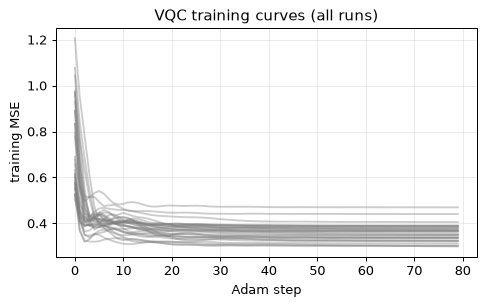

In [22]:
d = DS["NSL-KDD"]; t0 = time.time(); rows = []; curves = []
for g in GAMMAS:
    for rep in range(VQC_REPS):
        tr, te = draw_extraction(d, 250, 0.8, g, rep, tag=3)
        sc = MinMaxScaler().fit(d["Fe"]["PCA"][tr]); Xtr = sc.transform(d["Fe"]["PCA"][tr]); Xte = np.clip(sc.transform(d["Fe"]["PCA"][te]), 0, 1)
        acc, hist, _ = train_vqc(Xtr, d["ye"][tr], Xte, d["ye"][te], SEED + rep)
        o = fit_eval(d["Fe"]["PCA"], d["ye"], tr, te, models=("qsvm", "svm")); rows.append(dict(gamma=g, rep=rep, acc_vqc=acc, acc_qsvm=o["acc_qsvm"], acc_svm=o["acc_svm"])); curves.append(hist)
T6 = pd.DataFrame(rows); print(f"VQC runs finished in {time.time()-t0:.0f} s ({VQC_STEPS} Adam steps each, {VQC_REPS} extractions per mix)")
p6 = {0.60: .60, 0.50: .67, 0.55: .72}
g6 = T6.groupby("gamma")[["acc_vqc", "acc_qsvm", "acc_svm"]].mean()
tab6 = pd.DataFrame({"VQC (here)": [f"{g6.loc[g,'acc_vqc']:.2f}" for g in GAMMAS], "VQC (paper)": [f"{p6[g]:.2f}" for g in GAMMAS],
                     "QSVM same points": [f"{g6.loc[g,'acc_qsvm']:.2f}" for g in GAMMAS], "SVM-poly same points": [f"{g6.loc[g,'acc_svm']:.2f}" for g in GAMMAS]},
                    index=[f"({int(g*100)}%, {100-int(g*100)}%)" for g in GAMMAS])
print("TABLE VI (NSL-KDD, Z=250, PCA features)"); display(tab6)
plt.figure(figsize=(5.5, 3.5)); [plt.plot(h, c="gray", alpha=0.4) for h in curves]; plt.xlabel("Adam step"); plt.ylabel("training MSE"); plt.title("VQC training curves (all runs)"); plt.tight_layout(); plt.show()

## 12. Timing: what does inference cost?

The paper reports inference times of 460 s (SVM on the whole NSL-KDD test data), 73 s (QSVM, `Z` = 150) and 42 s (QSVM, `Z` = 250), and, in the overlap experiment, 0.015 s (SVM) vs 4.11 s (QSVM). Absolute times depend on hardware, simulator and test-set size, so only orders of magnitude and the structure are comparable. Three QSVM costs are measured here: the exact NumPy statevector kernel used in the main loop, Qiskit's `QSVC` + `FidelityStatevectorKernel` (a general statevector simulator, closest to what the authors ran), and the quadratic growth with `Z`.

In [23]:
d = DS["NSL-KDD"]; rows = []
for Z in (150, 250):
    tr, te = draw_extraction(d, Z, 0.8, None, 0)
    sc = MinMaxScaler().fit(d["Fe"]["PCA"][tr]); Xtr = ANGLE_SCALE * sc.transform(d["Fe"]["PCA"][tr]); Xte = ANGLE_SCALE * np.clip(sc.transform(d["Fe"]["PCA"][te]), 0, 1)
    t0 = time.perf_counter(); q = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=fm), C=QSVM_C).fit(Xtr, d["ye"][tr]); t1 = time.perf_counter()
    p = q.predict(Xte); t2 = time.perf_counter()
    o = fit_eval(d["Fe"]["PCA"], d["ye"], tr, te, models=("qsvm", "svm"))
    rows.append({"Z": Z, "train pts": len(tr), "test pts": len(te), "Qiskit QSVC fit [s]": round(t1 - t0, 2), "Qiskit QSVC predict [s]": round(t2 - t1, 2),
                 "NumPy QSVM predict [s]": round(o["t_inf_qsvm"], 4), "SVM-poly predict, same Z [s]": round(o["t_inf_svm"], 4),
                 "Qiskit acc": round(accuracy_score(d["ye"][te], p), 3), "NumPy acc": round(o["acc_qsvm"], 3)})
TIM = pd.DataFrame(rows); display(TIM)
t_big = big["NSL-KDD"]; print(f"SVM-poly trained on {BIG_TRAIN} flows: predict {t_big['n_test']} flows in {t_big['t_inf']:.2f} s = {1000*t_big['t_inf']/t_big['n_test']:.2f} ms per flow")
per_flow_q = TIM["Qiskit QSVC predict [s]"] / TIM["test pts"]; print("Qiskit QSVC predict time per test flow [ms]:", (1000 * per_flow_q).round(1).tolist())

,Z,train pts,test pts,Qiskit QSVC fit [s],Qiskit QSVC predict [s],NumPy QSVM predict [s],"SVM-poly predict, same Z [s]",Qiskit acc,NumPy acc
0,150,120,30,1.73,1.81,0.0044,0.0013,0.90,0.90
1,250,200,50,3.07,2.40,0.0089,0.0008,0.88,0.88


SVM-poly trained on 20000 flows: predict 10000 flows in 1.91 s = 0.19 ms per flow
Qiskit QSVC predict time per test flow [ms]: [60.3, 48.0]


## 13. Extra: does a tuned kernel bandwidth change the picture?

The fixed scale `ANGLE_SCALE = pi` is a choice. Here the bandwidth is chosen on a **validation split of the training data only** (25% of the training points, candidates `0.25, 0.5, 1, 2 x pi`) and the QSVM is re-evaluated on the same test points (NSL-KDD, PCA, `Z` = 250, 80/20).

In [24]:
SCALES = [0.25 * np.pi, 0.5 * np.pi, np.pi, 2 * np.pi]
d = DS["NSL-KDD"]; rows = []
for rep in range(N_REPS):
    tr, te = draw_extraction(d, 250, 0.8, None, rep); Fm, y = d["Fe"]["PCA"], d["ye"]
    tr_in, va = train_test_split(tr, test_size=0.25, stratify=y[tr], random_state=SEED)
    sc_in = MinMaxScaler().fit(Fm[tr_in]); A = sc_in.transform(Fm[tr_in]); V = np.clip(sc_in.transform(Fm[va]), 0, 1); val = []
    for s in SCALES:
        clf = SVC(kernel="precomputed", C=QSVM_C).fit(q_kernel(s * A), y[tr_in]); val.append(accuracy_score(y[va], clf.predict(q_kernel(s * V, s * A))))
    best = SCALES[int(np.argmax(val))]; sc = MinMaxScaler().fit(Fm[tr]); Xtr, Xte = sc.transform(Fm[tr]), np.clip(sc.transform(Fm[te]), 0, 1)
    clf = SVC(kernel="precomputed", C=QSVM_C).fit(q_kernel(best * Xtr), y[tr])
    rows.append(dict(rep=rep, best_scale_over_pi=best / np.pi, acc_tuned=accuracy_score(y[te], clf.predict(q_kernel(best * Xte, best * Xtr))), acc_fixed=fit_eval(Fm, y, tr, te, models=("qsvm",))["acc_qsvm"]))
TUNE = pd.DataFrame(rows); print(TUNE[["acc_fixed", "acc_tuned"]].agg(["mean", "std"]).round(3)); print("chosen scales / pi:", TUNE.best_scale_over_pi.value_counts().to_dict())

      acc_fixed  acc_tuned
mean      0.891      0.921
std       0.033      0.038
chosen scales / pi: {0.25: 15, 0.5: 4, 1.0: 1}


## 14. Side-by-side comparison with the paper

For every number the paper reports that this notebook can test, the table shows the paper's value, the notebook's value and a verdict: **reproduced** (within 2 accuracy points, or the qualitative statement holds), **exceeded here** (more than 2 points higher), **not reached here** (more than 2 points lower or the statement fails), or **cannot be checked**.

In [25]:
claims = []
def v_num(p, n): dlt = n - p; return "reproduced" if abs(dlt) <= TOL_ACC else ("exceeded here" if dlt > 0 else "not reached here")
def add(claim, paper, nb, verdict): claims.append(dict(claim=claim, paper=paper, notebook=nb, verdict=verdict))

# Tables I / II
p1 = {(2/3, 150): .85, (2/3, 250): .88, (.75, 150): .87, (.75, 250): .90, (.80, 150): .90, (.80, 250): .92}
for (a, z), p in p1.items():
    n = T1[(np.isclose(T1.alpha, a)) & (T1.Z == z)].acc_qsvm.mean(); add(f"Table I QSVM NSL-KDD, split {a:.2f}, Z={z}", p, round(n, 3), v_num(p, n))
p2 = {(.75, 200): .68, (.75, 300): .70, (.80, 200): .71, (.80, 300): .73}
for (a, z), p in p2.items():
    n = T2[(np.isclose(T2.alpha, a)) & (T2.Z == z)].acc_qsvm.mean(); add(f"Table II QSVM NB15, split {a:.2f}, Z={z}", p, round(n, 3), v_num(p, n))
add("Table I: SVM (whole dataset, 66.7/33.3) NSL-KDD", 0.80, round(big["NSL-KDD"]["acc"], 3), v_num(0.80, big["NSL-KDD"]["acc"]))
add("Table II: SVM (whole dataset) NB15", 0.60, round(big["NB15"]["acc"], 3), v_num(0.60, big["NB15"]["acc"]))
q150 = T1[(np.isclose(T1.alpha, .8)) & (T1.Z == 250)]
add("QSVM (80/20, Z=250) beats the large-data SVM on NSL-KDD", "QSVM > SVM by 8 points (Z=250)", f"QSVM {q150.acc_qsvm.mean():.3f} vs SVM {big['NSL-KDD']['acc']:.3f}", "reproduced" if q150.acc_qsvm.mean() > big["NSL-KDD"]["acc"] else "not reached here")
add("QSVM beats the SVM trained on the SAME Z points (fair comparison)", "implied by the fair-comparison experiment (overlap zones)", f"QSVM {T1.acc_qsvm.mean():.3f} vs SVM-poly {T1.acc_svm.mean():.3f} (all Table I runs)", "reproduced" if T1.acc_qsvm.mean() > T1.acc_svm.mean() + 0.005 else "not reached here")
mz = T1.groupby("Z").acc_qsvm.mean(); add("Accuracy increases with Z", "Z=250 > Z=150", f"{mz[250]:.3f} vs {mz[150]:.3f}", "reproduced" if mz[250] > mz[150] else "not reached here")
ma = T1.groupby("alpha").acc_qsvm.mean(); add("Accuracy increases with training fraction (80/20 best)", "0.85 -> 0.90 (Z=150)", " -> ".join(f"{v:.3f}" for v in ma.values), "reproduced" if ma.iloc[-1] >= ma.iloc[0] else "not reached here")
# Table III
for (g, m, z), p in paper3.items():
    n = T3[(T3.gamma == g) & (T3.method == m) & (T3.Z == z)].acc_qsvm.mean(); add(f"Table III {m}, ({int(g*100)}/{100-int(g*100)}), Z={z}", p, round(n, 3), v_num(p, n))
mg = T3.groupby("gamma").acc_qsvm.mean(); add("Best class mix is (55%, 45%) (NSL-KDD)", "(55,45) best for all methods", f"best = {int(mg.idxmax()*100)}/{100-int(mg.idxmax()*100)} ({mg.max():.3f})", "reproduced" if abs(mg.idxmax() - 0.55) < 1e-9 else "not reproduced")
mm = T3.groupby("method").acc_qsvm.mean(); add("VAE is the best fusion method (NSL-KDD)", "VAE > BE > PCA", " > ".join(f"{k} {mm[k]:.3f}" for k in mm.sort_values(ascending=False).index), "reproduced" if mm.idxmax() == "VAE" else "not reproduced")
sd = T3.groupby("method").acc_qsvm.std(); add("VAE has the smallest spread (Figs. 2-3)", "smallest variance for VAE", ", ".join(f"{k} {sd[k]:.3f}" for k in ["BE", "VAE", "PCA"]), "reproduced" if sd.idxmin() == "VAE" else "not reproduced")
# Table IV
mean4 = T4.loc["mean"]
add("Table IV: outlier accuracy", 0.70, round(mean4["outlier"], 3), v_num(0.70, mean4["outlier"]))
add("Table IV: +5% intra-class", 0.83, round(mean4["+5% intra"], 3), v_num(0.83, mean4["+5% intra"]))
add("Table IV: +10% inter-class", 0.50, round(mean4["+10% inter"], 3), v_num(0.50, mean4["+10% inter"]))
add("Table IV: intra-class additions help, inter-class additions hurt", "intra +13 points, inter -20 points", f"intra5 {mean4['+5% intra']-mean4['outlier']:+.3f}, inter10 {mean4['+10% inter']-mean4['outlier']:+.3f}, random10 {mean4['+10% random (control)']-mean4['outlier']:+.3f}",
    "reproduced" if (mean4["+5% intra"] > mean4["outlier"] and mean4["+10% inter"] < mean4["+10% intra"]) else "not reproduced")
# Table V
for (g, z), p in p5.items():
    n = T5[(T5.method == "VAE") & (T5.gamma == g) & (T5.Z == z)].acc_qsvm.mean(); add(f"Table V VAE NB15, ({int(g*100)}/{100-int(g*100)}), Z={z}", p, round(n, 3), v_num(p, n))
add("Table V: VAE better than PCA on NB15 (Z=300, 80/20)", "0.89 vs 0.73", f"VAE {T5[(T5.method=='VAE')&(T5.Z==300)].acc_qsvm.mean():.3f} vs PCA {T5[(T5.method=='PCA')&(T5.Z==300)].acc_qsvm.mean():.3f} (class mixes controlled)", "reproduced" if T5[(T5.method=='VAE')&(T5.Z==300)].acc_qsvm.mean() > T5[(T5.method=='PCA')&(T5.Z==300)].acc_qsvm.mean() else "not reproduced")
# Overlap experiment
add("Overlap: SVM accuracy range", "0.32 - 0.59", f"{OV.acc_svm.min():.2f} - {OV.acc_svm.max():.2f} (mean {OV.acc_svm.mean():.2f})", "reproduced" if (OV.acc_svm.mean() <= 0.59 + TOL_ACC and OV.acc_svm.mean() >= 0.32 - TOL_ACC) else "not reached here")
add("Overlap: QSVM accuracy range", "0.50 - 0.68", f"{OV.acc_qsvm.min():.2f} - {OV.acc_qsvm.max():.2f} (mean {OV.acc_qsvm.mean():.2f})", "reproduced" if (OV.acc_qsvm.mean() <= 0.68 + TOL_ACC and OV.acc_qsvm.mean() >= 0.50 - TOL_ACC) else "not reached here")
add("Overlap: QSVM more accurate than SVM on identical points", "QSVM > SVM", f"{OV.acc_qsvm.mean():.3f} vs {OV.acc_svm.mean():.3f}", "reproduced" if OV.acc_qsvm.mean() > OV.acc_svm.mean() else "not reproduced")
add("Overlap: QSVM much slower than SVM at inference", "4.11 s vs 0.015 s", f"Qiskit-statevector QSVC: see timing table; NumPy QSVM {OV.t_inf_qsvm.mean():.4f} s vs SVM {OV.t_inf_svm.mean():.4f} s", "cannot be checked (simulator-dependent)")
# Table VI
for g, p in p6.items():
    n = T6[T6.gamma == g].acc_vqc.mean(); add(f"Table VI VQC, ({int(g*100)}/{100-int(g*100)})", p, round(n, 3), v_num(p, n))
add("VQC is worse than QSVM and than SVM", "VQC < SVM, VQC < QSVM", f"VQC {T6.acc_vqc.mean():.3f}, QSVM {T6.acc_qsvm.mean():.3f}, SVM {T6.acc_svm.mean():.3f}", "reproduced" if (T6.acc_vqc.mean() < T6.acc_qsvm.mean() and T6.acc_vqc.mean() < T6.acc_svm.mean() + 0.005) else "not reproduced")
vg = T6.groupby("gamma").acc_vqc.mean(); add("VQC: best mix is (55%, 45%)", "0.72 best", f"best = {int(vg.idxmax()*100)}/{100-int(vg.idxmax()*100)}", "reproduced" if abs(vg.idxmax() - 0.55) < 1e-9 else "not reproduced")
# reconstruction and circuit size
for m, p in [("BE", .0059), ("VAE", .0051), ("PCA", .008)]:
    n = fusion_df.loc["NSL-KDD", m]   # lower is better, so a smaller MSE than the paper counts as "exceeded here"
    add(f"Reconstruction MSE {m} (NSL-KDD; lower is better)", p, round(n, 4), "reproduced" if abs(n - p) <= max(0.002, 0.3 * p) else ("exceeded here" if n < p else "not reached here"))
add("QSVM circuit: 4 qubits, feature-map depth 2", "4 qubits, depth 2 (baseline [9]: more than 4 qubits, depth 5)", f"{N_QUBITS} qubits, {FM_REPS} repetitions, gate depth {transpile(fm, basis_gates=['h','p','cx'], optimization_level=0).depth()}", "reproduced (2 repetitions; gate depth is larger)")
add("Inference: QSVM faster than SVM on NSL-KDD (460 s vs 73 s / 42 s)", "460 s vs 73 s (Z=150) vs 42 s (Z=250)", "see section 12 (different hardware, simulator and test-set size)", "cannot be checked")
CMP = pd.DataFrame(claims); pd.set_option("display.max_colwidth", 90, "display.width", 200, "display.max_rows", 200)
display(CMP)
cat = CMP.verdict.str.extract(r"^(reproduced|exceeded here|not reached here|not reproduced|cannot be checked)")[0]
print("Verdict counts:"); print(cat.value_counts().to_string())

,claim,paper,notebook,verdict
0,"Table I QSVM NSL-KDD, split 0.67, Z=150",0.85,0.907,exceeded here
1,"Table I QSVM NSL-KDD, split 0.67, Z=250",0.88,0.887,reproduced
2,"Table I QSVM NSL-KDD, split 0.75, Z=150",0.87,0.883,reproduced
3,"Table I QSVM NSL-KDD, split 0.75, Z=250",0.9,0.893,reproduced
4,"Table I QSVM NSL-KDD, split 0.80, Z=150",0.9,0.883,reproduced
5,"Table I QSVM NSL-KDD, split 0.80, Z=250",0.92,0.891,not reached here
6,"Table II QSVM NB15, split 0.75, Z=200",0.68,0.892,exceeded here
7,"Table II QSVM NB15, split 0.75, Z=300",0.7,0.907,exceeded here
8,"Table II QSVM NB15, split 0.80, Z=200",0.71,0.879,exceeded here
9,"Table II QSVM NB15, split 0.80, Z=300",0.73,0.912,exceeded here


Verdict counts:
0
not reached here     25
exceeded here        14
reproduced           14
not reproduced        7
cannot be checked     2


## Reading the paper critically

The numbers quoted below are from the full run (`FAST_MODE = False`, 20 extractions, 20,000-flow fit pools); the `FAST_MODE` run shows the same picture with larger noise.

1. **What reproduces.** The *level* of the NSL-KDD QSVM accuracies in Table I (about 0.88-0.91 here, 0.85-0.92 in the paper), the 4-qubit ZZ-feature-map QSVM pipeline itself, the reconstruction error of the basic autoencoder (0.0052 vs 0.0059), the large spread of single draws (individual extractions range from about 0.73 to 1.00, Figs. 2-3), the overlap-zone accuracies being poor and near 0.5-0.6, and the preference for the (55%, 45%) mix in the VQC.
2. **The headline "QSVM beats SVM by 5-13 points" does not survive a fair comparison.** The paper's SVM numbers (0.80 NSL-KDD, 0.60 NB15) are quoted from another paper with another preprocessing. On *exactly the same 4 inputs*, a plain polynomial SVM trained on the same 200-250 points reaches about 0.91, a random forest about 0.94, and even a polynomial SVM trained on 20,000 flows reaches 0.94. The QSVM (0.89 with the fixed `pi` scale) is at best on par. The paper's own closing experiment (overlap zones) is the only fair comparison, and it is also what the notebook finds: SVM and QSVM are indistinguishable (0.58 vs 0.58) there, with the random forest slightly better.
3. **NB15 is not the same dataset.** With the paper's own class prior (21.6% attacks) the trivial "always normal" classifier already scores 0.78, higher than every NB15 number in the paper (0.60-0.89 for Tables II and V). On the public official partition and with frequency-encoded features all models score 0.88-0.92, which is again close to what a classical model achieves; the balanced accuracy of the QSVM (0.75-0.82) is the more honest figure. The paper's low NB15 numbers point to a different subset or preprocessing, which cannot be recovered from the text.
4. **Most differences in Tables III and V are inside the noise.** With only 30-50 test points a single error costs 2-3.3 accuracy points, the standard deviation over draws is about 0.05, and the paper reports means over 20 draws with no confidence interval (standard error about 0.011). Here the three fusion methods differ by less than one point (BE 0.889, PCA 0.880, VAE 0.874); the paper's ordering VAE > BE > PCA, the claim that the VAE has the smallest variance, and the (55%, 45%) optimum are **not reproduced** (best mix here: 50/50). The extra autoencoders also introduce unreported choices (loss weighting, activations, learning rate, which data they are fitted on) that move the results as much as the claimed gaps.
5. **Table IV (outlier analysis) is not reproduced and needs a control.** Adding 5% or 10% extra attack points changed the worst draws by at most +-0.01 here, whether "intra-class" or "inter-class"; the random-point control behaves the same. The paper's jump from 0.70 to 0.83 (and the fall to 0.50) rests on a single draw. Picking the worst draw and measuring it again also invites regression to the mean; the paper does not control for it.
6. **The VQC comparison depends on unreported training details.** With a small, well-trained amplitude-encoding VQC (2 qubits, 18 parameters) the accuracy is 0.90-0.91, equal to the QSVM and far above the paper's 0.60-0.72. The statement "QSVM is better suited than VQC" therefore says more about the paper's VQC training budget than about the models. Note also that amplitude encoding stores only the *direction* of the 4 features, which is a strong normalisation.
7. **Speed claims.** The paper compares a SVM predicting all test flows (460 s) with a QSVM predicting a few dozen (73 s / 42 s). Here a polynomial SVM predicts 10,000 flows in about 2 s (0.2 ms per flow), while Qiskit's statevector QSVM needs about 75 ms per flow: every test flow needs one circuit evaluation per training point. QSVM inference cost grows linearly with the training-set size and, on real hardware with shots, would be far higher. The inference-time argument for QSVM is not supported.
8. **"Depth 2".** The paper counts feature-map repetitions. The decomposed 4-qubit ZZ map with two repetitions has gate depth 31 (h/p/cx), the kernel circuit 63; comparing "depth 2" with the baseline's "depth 5" mixes two different notions of depth.
9. **Kernel bandwidth matters more than the fusion method.** Choosing the angle scale on a validation split (section 13) raises the QSVM from about 0.89 to 0.92, more than any fusion-method difference in Table III. The paper does not say how the features were scaled before the circuit.
10. **Scope.** The experiments use NSL-KDD and NB15; nothing here is specific to 5G, and the simulation is noiseless. The abstract's "5G and beyond" and the hardware-friendliness argument (few qubits, shallow depth) are untested claims.

## Exercises

1. **Entanglement.** Change `ENTANGLEMENT` to `"linear"` and re-run Tables I and III. Does the kernel (and the accuracy) depend on the number of ZZ pairs? Why could the paper's "depth 2" claim depend on this choice?
2. **Where the encoders are fitted.** The notebook fits PCA/BE/VAE on a disjoint unlabelled pool. Change `build_dataset` so that PCA is fitted only on the `Z` points of each extraction (the strictest leak-free reading) and compare Table I. Which fusion method suffers most from having only 120-200 fit points?
3. **Bandwidth.** Section 13 tunes the angle scale on a validation split. Extend the grid, add `C`, and report whether the tuned QSVM still beats the SVM-poly with tuned `degree` and `C` on identical points.
4. **Majority baseline.** On NB15 (21.6% attacks) compute the balanced accuracy of QSVM, SVM and RF for the natural mix. Is Table II's accuracy better than predicting "normal" for everything?
5. **Noise.** Replace the exact kernel with the shot-based `AerSimulator` kernel (`aer_kernel_entry`) at 1,024 shots and a `FakeBrisbane` noise model from `qiskit_ibm_runtime.fake_provider` for `Z` = 100. How much does the accuracy drop, and why is the paper's inference time of seconds optimistic for hardware?